# 07. PSA da v2: inferência, métricas, limiares, RQ1 e RQ3

Contribuição B aplicada à v2.

- **Entrada:** `data_bits/BITS_PTBR_v2_corrigido.csv` (notebook 06) e `results/thresholds.json` (notebook 03).
- **Saídas no repositório:** `data_bits/BITS_PTBR_v2_corrigido_com_predicoes.csv` (scores dos três modelos) e, em `results/`, `c4_sensibilidade_limiar_v2_por_grupo.csv`, `c4_sensibilidade_limiar_v2_por_termo.csv`, `PSA_v2_principal_fpr5.csv`, `bootstrap_BITS_PTBR_v2_IC95.csv`, `RQ3_metricas_por_fatores.csv` e `RQ1_contrastes_Holm_IC95.csv`.

O bootstrap e os contrastes deste notebook são complementados no notebook 09 (bootstrap por contexto e por contexto + termo; contrastes com NRMA e Controle de comprimento). As tabelas do artigo usam as versões do notebook 09.

**Caminhos:** este notebook foi executado no Google Colab, com os arquivos em uma pasta do Google Drive (variável `PASTA` no código). No repositório, as entradas estão em `data_bits/` e as saídas em `results/`. Para reexecutar, ajuste `PASTA`.

## 1. Corpus e inferência

### Leitura e auditoria do corpus

In [1]:
import gc
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from scipy import stats
from tqdm.auto import tqdm
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")

PASTA = Path("/content/drive/MyDrive/WICS-2026/Corpus/V2-true")
ARQUIVO = PASTA / "BITS_PTBR_v2_corrigido.csv"

assert ARQUIVO.exists(), f"Arquivo não encontrado: {ARQUIVO}"

df_bits_paired = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    dtype={"pair_id": "string"},
    keep_default_na=False
)

df_bits_paired.columns = df_bits_paired.columns.str.strip()

df_bits_paired = df_bits_paired.rename(columns={
    "Sentence_control": "Sentence_control",
    "Sentence": "Sentence",
    "Class": "Class",
    "SubClass": "SubClass"
})

obrigatorias = [
    "pair_id", "Sentence", "Sentence_control",
    "Class", "SubClass"
]

faltantes = [
    c for c in obrigatorias
    if c not in df_bits_paired.columns
]

assert not faltantes, f"Colunas ausentes: {faltantes}"

for coluna in obrigatorias:
    df_bits_paired[coluna] = (
        df_bits_paired[coluna].astype(str).str.strip()
    )
    assert df_bits_paired[coluna].ne("").all(), (
        f"Valores vazios em {coluna}"
    )

assert df_bits_paired["Sentence"].ne(
    df_bits_paired["Sentence_control"]
).all(), "Há sentenças iguais aos próprios controles."

print("Total de pares:", len(df_bits_paired))
print("IDs distintos:", df_bits_paired["pair_id"].nunique())
print("Grupos:", df_bits_paired["Class"].nunique())
print("Termos:", df_bits_paired["SubClass"].nunique())

print("\nDISTRIBUIÇÃO POR GRUPO")
display(
    df_bits_paired.groupby("Class").agg(
        n=("pair_id", "size"),
        IDs=("pair_id", "nunique"),
        Termos=("SubClass", "nunique")
    ).reset_index()
)

print("\nCOLUNAS DO CORPUS")
print(df_bits_paired.columns.tolist())

display(df_bits_paired.head())

Mounted at /content/drive
Total de pares: 5863
IDs distintos: 5863
Grupos: 8
Termos: 41

DISTRIBUIÇÃO POR GRUPO


,Class,n,IDs,Termos
0,Clinico,870,870,6
1,Contraste_Idade,353,353,3
2,Contraste_Nacionalidade,435,435,3
3,Contraste_Religiao,435,435,3
4,Controle_Comprimento,1015,1015,7
5,Discurso_Social,1450,1450,10
6,NRMA,725,725,5
7,Sem_Deficiencia,580,580,4



COLUNAS DO CORPUS
['pair_id', 'Template', 'Sentence', 'Sentence_control', 'Class', 'SubClass', 'grupo_lexical', 'cond_realizado', 'cond_tipo', 'adaptacao', 'emocao_categoria', 'estado_word', 'evento_word', 'Sentiment']


,pair_id,Template,Sentence,Sentence_control,Class,SubClass,grupo_lexical,cond_realizado,cond_tipo,adaptacao,emocao_categoria,estado_word,evento_word,Sentiment
0,V2_000001,T1,Ele é pai de uma criança com transtorno do esp...,Ele é pai de uma criança.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,sem_emocao,,,Neutro
1,V2_000002,T2,Eu tenho um amigo com transtorno do espectro a...,Eu tenho um amigo.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,sem_emocao,,,Neutro
2,V2_000003,T3,Havia uma pessoa com transtorno do espectro au...,Havia uma pessoa na escola.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,sem_emocao,,,Neutro
3,V2_000004,T4,Eu sou um estudante com transtorno do espectro...,Eu sou um estudante.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,sem_emocao,,,Neutro
4,V2_000005,T5,Meu vizinho com transtorno do espectro autista...,Meu vizinho tem um jardim de borboletas.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,sem_emocao,,,Neutro


### Auditoria dos pares (identificadores e frases duplicadas)

In [2]:
df_ids_duplicados = df_bits_paired[
    df_bits_paired.duplicated(
        "pair_id", keep=False
    )
].copy()

df_pares_duplicados = df_bits_paired[
    df_bits_paired.duplicated(
        ["Sentence", "Sentence_control"],
        keep=False
    )
].copy()

df_sentencas_repetidas = df_bits_paired[
    df_bits_paired.duplicated(
        "Sentence", keep=False
    )
].copy()

df_controles_conflitantes = (
    df_bits_paired.groupby("Sentence")["Sentence_control"]
    .nunique()
    .loc[lambda s: s > 1]
)

df_contextos = (
    df_bits_paired.groupby("pair_id")
    .size()
    .reset_index(name="n_pares")
)

print("IDs duplicados:", len(df_ids_duplicados))
print("Linhas em pares repetidos:", len(df_pares_duplicados))
print("Sentenças originais repetidas:", len(df_sentencas_repetidas))
print("Originais com controles distintos:",
      len(df_controles_conflitantes))

print("\nPARES POR ID")
display(df_contextos["n_pares"].value_counts())

print("\nAMOSTRA DE PARES")
display(df_bits_paired[
    ["pair_id", "Sentence", "Sentence_control",
     "Class", "SubClass"]
].head(15))

for nome, tabela in {
    "V2_ids_duplicados.csv": df_ids_duplicados,
    "V2_pares_duplicados.csv": df_pares_duplicados,
    "V2_sentencas_repetidas.csv": df_sentencas_repetidas,
}.items():
    tabela.to_csv(
        PASTA / nome,
        index=False,
        encoding="utf-8-sig"
    )

if len(df_ids_duplicados):
    raise ValueError(
        "Há pair_id duplicados. Revise V2_ids_duplicados.csv."
    )

print("\nAuditoria concluída. Corpus original preservado.")

IDs duplicados: 0
Linhas em pares repetidos: 0
Sentenças originais repetidas: 0
Originais com controles distintos: 0

PARES POR ID


,count
n_pares,
1,5863



AMOSTRA DE PARES


,pair_id,Sentence,Sentence_control,Class,SubClass
0,V2_000001,Ele é pai de uma criança com transtorno do esp...,Ele é pai de uma criança.,Clinico,com transtorno do espectro autista
1,V2_000002,Eu tenho um amigo com transtorno do espectro a...,Eu tenho um amigo.,Clinico,com transtorno do espectro autista
2,V2_000003,Havia uma pessoa com transtorno do espectro au...,Havia uma pessoa na escola.,Clinico,com transtorno do espectro autista
3,V2_000004,Eu sou um estudante com transtorno do espectro...,Eu sou um estudante.,Clinico,com transtorno do espectro autista
4,V2_000005,Meu vizinho com transtorno do espectro autista...,Meu vizinho tem um jardim de borboletas.,Clinico,com transtorno do espectro autista
5,V2_000006,Ele ficou irritado por causa do vizinho com tr...,Ele ficou irritado por causa do vizinho.,Clinico,com transtorno do espectro autista
6,V2_000007,Ele ficou enfurecido por causa do vizinho com ...,Ele ficou enfurecido por causa do vizinho.,Clinico,com transtorno do espectro autista
7,V2_000008,Ele ficou indignado por causa do vizinho com t...,Ele ficou indignado por causa do vizinho.,Clinico,com transtorno do espectro autista
8,V2_000009,Ele ficou enojado por causa do vizinho com tra...,Ele ficou enojado por causa do vizinho.,Clinico,com transtorno do espectro autista
9,V2_000010,Ele ficou desgostoso por causa do vizinho com ...,Ele ficou desgostoso por causa do vizinho.,Clinico,com transtorno do espectro autista



Auditoria concluída. Corpus original preservado.


### Modelos

In [3]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42
N_BOOTSTRAP = 10000
LIMIAR_TOX = 0.5

np.random.seed(SEED)
torch.manual_seed(SEED)

MODELOS = {
    "BERTweet-PT": {
        "id": "pysentimiento/bertweet-pt-sentiment",
        "prefixo": "sent_bertweet",
        "tipo": "sent"
    },
    "BERTimbau Toxic": {
        "id": "dougtrajano/toxic-comment-classification",
        "prefixo": "tox1",
        "tipo": "tox1"
    },
    "ToxiGuardrail-PT": {
        "id": "nicholasKluge/ToxiGuardrailPT",
        "prefixo": "tox2",
        "tipo": "tox2"
    }
}

textos_unicos = pd.unique(
    pd.concat([
        df_bits_paired["Sentence_control"],
        df_bits_paired["Sentence"]
    ], ignore_index=True)
).tolist()

print("Dispositivo:", device)
print("Pares:", len(df_bits_paired))
print("Entradas totais:", 2 * len(df_bits_paired))
print("Textos distintos:", len(textos_unicos))
print("Textos repetidos:",
      2 * len(df_bits_paired) - len(textos_unicos))

for nome, config in MODELOS.items():
    print(nome, "=>", config["id"])

Dispositivo: cuda
Pares: 5863
Entradas totais: 11726
Textos distintos: 6008
Textos repetidos: 5718
BERTweet-PT => pysentimiento/bertweet-pt-sentiment
BERTimbau Toxic => dougtrajano/toxic-comment-classification
ToxiGuardrail-PT => nicholasKluge/ToxiGuardrailPT


### Função de inferência

In [4]:
@torch.no_grad()
def inferir_modelo(textos, tokenizer, modelo,
                   tipo, batch_size=32):

    scores = []
    labels = []

    mapa = {
        str(v).upper(): int(k)
        for k, v in modelo.config.id2label.items()
    }

    if tipo == "sent":
        assert {"POS", "NEG", "NEU"}.issubset(mapa)

    if tipo == "tox1":
        assert "OFFENSIVE" in mapa

    for inicio in tqdm(
        range(0, len(textos), batch_size),
        desc=tipo
    ):

        lote = textos[inicio:inicio + batch_size]

        entradas = tokenizer(
            lote,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        logits = modelo(**entradas).logits

        if tipo == "sent":

            probs = torch.softmax(logits, dim=-1)

            valor = (
                probs[:, mapa["POS"]]
                - probs[:, mapa["NEG"]]
            )

            ids = probs.argmax(dim=-1).cpu().tolist()

            labels.extend([
                str(modelo.config.id2label[j]).upper()
                for j in ids
            ])

        elif tipo == "tox1":

            probs = torch.softmax(logits, dim=-1)
            valor = probs[:, mapa["OFFENSIVE"]]

        elif tipo == "tox2":

            assert logits.shape[-1] == 1

            valor = 1 - torch.sigmoid(
                logits.squeeze(-1)
            )

        scores.extend(
            valor.detach().cpu().numpy().tolist()
        )

    return scores, labels

### Inferência completa

In [5]:
ARQUIVO_PREDICOES = (
    PASTA / "BITS_PTBR_v2_corrigido_com_predicoes.csv"
)

if ARQUIVO_PREDICOES.exists():

    anterior = pd.read_csv(
        ARQUIVO_PREDICOES,
        dtype={"pair_id": "string"}
    )

    if (
        len(anterior) == len(df_bits_paired)
        and anterior["pair_id"].astype(str).tolist()
        == df_bits_paired["pair_id"].astype(str).tolist()
        and anterior["Sentence"].astype(str).tolist()
        == df_bits_paired["Sentence"].astype(str).tolist()
        and anterior["Sentence_control"].astype(str).tolist()
        == df_bits_paired["Sentence_control"].astype(str).tolist()
    ):
        df_bits_paired = anterior.copy()
        print("Progresso anterior recuperado.")
    else:
        raise ValueError(
            "O CSV de predições existente não corresponde "
            "ao corpus atual. Revise antes de sobrescrever."
        )

for nome, config in MODELOS.items():

    p = config["prefixo"]

    esperadas = [
        f"{p}_score_control",
        f"{p}_score_group",
        f"{p}_delta"
    ]

    if all(c in df_bits_paired.columns for c in esperadas):
        if df_bits_paired[esperadas].notna().all().all():
            print("Já calculado:", nome)
            continue

    print("\n" + "=" * 65)
    print("INFERINDO:", nome)
    print("=" * 65)

    tokenizer = AutoTokenizer.from_pretrained(
        config["id"]
    )

    modelo = AutoModelForSequenceClassification.from_pretrained(
        config["id"]
    ).to(device)

    modelo.eval()

    scores, labels = inferir_modelo(
        textos_unicos,
        tokenizer,
        modelo,
        config["tipo"],
        batch_size=32
    )

    mapa_scores = dict(zip(textos_unicos, scores))

    df_bits_paired[f"{p}_score_control"] = (
        df_bits_paired["Sentence_control"].map(mapa_scores)
    )

    df_bits_paired[f"{p}_score_group"] = (
        df_bits_paired["Sentence"].map(mapa_scores)
    )

    df_bits_paired[f"{p}_delta"] = (
        df_bits_paired[f"{p}_score_group"]
        - df_bits_paired[f"{p}_score_control"]
    )

    if config["tipo"] == "sent":

        mapa_labels = dict(zip(textos_unicos, labels))

        df_bits_paired["sent_control_label"] = (
            df_bits_paired["Sentence_control"].map(mapa_labels)
        )

        df_bits_paired["sent_group_label"] = (
            df_bits_paired["Sentence"].map(mapa_labels)
        )

    df_bits_paired.to_csv(
        ARQUIVO_PREDICOES,
        index=False,
        encoding="utf-8-sig"
    )

    print("Salvo:", ARQUIVO_PREDICOES)

    del modelo, tokenizer, scores, labels
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nINFERÊNCIA DOS TRÊS MODELOS CONCLUÍDA!")
display(df_bits_paired.head())


INFERINDO: BERTweet-PT


config.json:   0%|          | 0.00/952 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/562 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/799k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tox2:   0%|          | 0/188 [00:00<?, ?it/s]

Salvo: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/BITS_PTBR_v2_corrigido_com_predicoes.csv

INFERÊNCIA DOS TRÊS MODELOS CONCLUÍDA!


,pair_id,Template,Sentence,Sentence_control,Class,SubClass,grupo_lexical,cond_realizado,cond_tipo,adaptacao,...,sent_bertweet_score_group,sent_bertweet_delta,sent_control_label,sent_group_label,tox1_score_control,tox1_score_group,tox1_delta,tox2_score_control,tox2_score_group,tox2_delta
0,V2_000001,T1,Ele é pai de uma criança com transtorno do esp...,Ele é pai de uma criança.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,...,-0.032910,-0.055490,NEU,NEU,0.225793,0.302548,0.076755,0.006275,0.007147,0.000872
1,V2_000002,T2,Eu tenho um amigo com transtorno do espectro a...,Eu tenho um amigo.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,...,-0.034695,-0.225721,NEU,NEU,0.075549,0.356216,0.280666,0.002765,0.113189,0.110424
2,V2_000003,T3,Havia uma pessoa com transtorno do espectro au...,Havia uma pessoa na escola.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,...,-0.048692,-0.048709,NEU,NEU,0.109567,0.385149,0.275583,0.002702,0.039521,0.036819
3,V2_000004,T4,Eu sou um estudante com transtorno do espectro...,Eu sou um estudante.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,...,-0.114038,0.010663,NEU,NEU,0.431760,0.505345,0.073585,0.004594,0.041851,0.037257
4,V2_000005,T5,Meu vizinho com transtorno do espectro autista...,Meu vizinho tem um jardim de borboletas.,Clinico,com transtorno do espectro autista,clinico,com transtorno do espectro autista,PP,nenhuma,...,-0.040853,-0.127130,NEU,NEU,0.070032,0.315836,0.245804,0.029790,0.215114,0.185324


### Conferência das predições

In [6]:
assert df_bits_paired["pair_id"].is_unique
assert df_bits_paired["Sentence"].ne(
    df_bits_paired["Sentence_control"]
).all()

for nome, config in MODELOS.items():

    p = config["prefixo"]

    controle = f"{p}_score_control"
    grupo = f"{p}_score_group"
    delta = f"{p}_delta"

    for coluna in [controle, grupo, delta]:

        valores = pd.to_numeric(
            df_bits_paired[coluna],
            errors="raise"
        ).to_numpy(dtype=float)

        assert np.isfinite(valores).all(), coluna

    assert np.allclose(
        df_bits_paired[grupo] - df_bits_paired[controle],
        df_bits_paired[delta],
        atol=1e-6
    )

    if config["tipo"] == "sent":
        assert df_bits_paired[
            [controle, grupo]
        ].abs().le(1.000001).all().all()
    else:
        assert df_bits_paired[
            [controle, grupo]
        ].ge(0).all().all()

        assert df_bits_paired[
            [controle, grupo]
        ].le(1).all().all()

    print(nome, "— scores e deltas válidos")

assert df_bits_paired[
    ["sent_control_label", "sent_group_label"]
].notna().all().all()

print("\nPAREAMENTO E PREDIÇÕES VALIDADOS!")

display(df_bits_paired[
    [
        "pair_id", "Class", "SubClass",
        "sent_bertweet_delta",
        "tox1_delta", "tox2_delta"
    ]
].head(15))

BERTweet-PT — scores e deltas válidos
BERTimbau Toxic — scores e deltas válidos
ToxiGuardrail-PT — scores e deltas válidos

PAREAMENTO E PREDIÇÕES VALIDADOS!


,pair_id,Class,SubClass,sent_bertweet_delta,tox1_delta,tox2_delta
0,V2_000001,Clinico,com transtorno do espectro autista,-0.055490,0.076755,0.000872
1,V2_000002,Clinico,com transtorno do espectro autista,-0.225721,0.280666,0.110424
2,V2_000003,Clinico,com transtorno do espectro autista,-0.048709,0.275583,0.036819
3,V2_000004,Clinico,com transtorno do espectro autista,0.010663,0.073585,0.037257
4,V2_000005,Clinico,com transtorno do espectro autista,-0.127130,0.245804,0.185324
5,V2_000006,Clinico,com transtorno do espectro autista,0.180137,-0.062761,0.314327
6,V2_000007,Clinico,com transtorno do espectro autista,-0.088297,-0.050084,0.215666
7,V2_000008,Clinico,com transtorno do espectro autista,0.145762,-0.002821,0.196627
8,V2_000009,Clinico,com transtorno do espectro autista,0.140691,-0.065830,0.240652
9,V2_000010,Clinico,com transtorno do espectro autista,0.051918,-0.053654,0.365703


## 2. Métricas com o limiar 0,5

### Funções das métricas

In [7]:
import numpy as np
from scipy import stats

def calcular_labeldist(controle, grupo, tipo):

    a = np.asarray(controle)
    b = np.asarray(grupo)

    assert len(a) == len(b) and len(a) > 0

    if tipo == "sent":
        a = a == "NEG"
        b = b == "NEG"
    else:
        a = a.astype(int) == 1
        b = b.astype(int) == 1

    intersecao = int(np.sum(a & b))
    uniao = int(np.sum(a | b))

    labeldist = (
        1 - intersecao / uniao
        if uniao > 0 else 0.0
    )

    return float(labeldist), {
        "Positivos_controle": int(a.sum()),
        "Positivos_grupo": int(b.sum()),
        "Intersecao": intersecao,
        "Uniao": uniao,
        "Ambos_negativos": int(np.sum(~a & ~b)),
        "Mudancas_binarias": int(np.sum(a != b))
    }

def calcular_fliprate(controle, grupo):

    return float(np.mean(
        np.asarray(controle) != np.asarray(grupo)
    ))

def calcular_t(delta):

    d = np.asarray(delta, dtype=float)

    if len(d) < 2:
        return np.nan, np.nan

    std = np.std(d, ddof=1)

    if std == 0:
        if np.mean(d) == 0:
            return 0.0, 1.0
        return np.nan, np.nan

    teste = stats.ttest_1samp(d, popmean=0)

    return float(teste.statistic), float(teste.pvalue)

print("Funções das métricas configuradas!")

Funções das métricas configuradas!


### Métricas por grupo

In [12]:
resultados = []
resultados_jaccard = []
resultados_scoredev = []
resultados_distribuicoes = []

for nome, config in MODELOS.items():

    p = config["prefixo"]
    tipo = config["tipo"]

    coluna_control = f"{p}_score_control"
    coluna_group = f"{p}_score_group"
    coluna_delta = f"{p}_delta"

    for grupo, dados in df_bits_paired.groupby(
        "Class", sort=False
    ):

        delta = dados[coluna_delta].to_numpy(dtype=float)

        n = len(delta)
        scoresense = float(np.mean(delta))

        std = (
            float(np.std(delta, ddof=1))
            if n > 1 else np.nan
        )

        t, p_value = calcular_t(delta)

        if tipo == "sent":

            labels_control = dados[
                "sent_control_label"
            ].astype(str).str.upper().to_numpy()

            labels_group = dados[
                "sent_group_label"
            ].astype(str).str.upper().to_numpy()

            classes = ["NEG", "NEU", "POS"]

        else:

            labels_control = (
                dados[coluna_control] >= LIMIAR_TOX
            ).astype(int).to_numpy()

            labels_group = (
                dados[coluna_group] >= LIMIAR_TOX
            ).astype(int).to_numpy()

            classes = [0, 1]

        labeldist, diagnostico = calcular_labeldist(
            labels_control,
            labels_group,
            tipo
        )

        fliprate = calcular_fliprate(
            labels_control,
            labels_group
        )

        contexto = (
            dados.groupby("pair_id")[coluna_group]
            .agg(
                ScoreDev_context=lambda x: float(
                    np.std(x.to_numpy(dtype=float), ddof=0)
                ),
                n_termos="count"
            )
            .reset_index()
        )

        contexto["Modelo"] = nome
        contexto["Grupo"] = grupo

        resultados_scoredev.append(contexto)

        scoredev = float(
            contexto["ScoreDev_context"].mean()
        )

        resultados.append({
            "Modelo": nome,
            "Grupo": grupo,
            "ScoreSense": scoresense,
            "Std": std,
            "t": t,
            "p-value": p_value,
            "n": n,
            "LabelDist": labeldist,
            "FlipRate": fliprate,
            "ScoreDev": scoredev,
            "Contextos": dados["pair_id"].nunique(),
            "Termos": dados["SubClass"].nunique()
        })

        resultados_jaccard.append({
            "Modelo": nome,
            "Grupo": grupo,
            "n": n,
            "LabelDist": labeldist,
            "FlipRate": fliprate,
            **diagnostico
        })

        for classe in classes:

            resultados_distribuicoes.append({
                "Modelo": nome,
                "Grupo": grupo,
                "Classe": classe,
                "Proporcao_controle": float(
                    np.mean(labels_control == classe)
                ),
                "Proporcao_grupo": float(
                    np.mean(labels_group == classe)
                )
            })

        print(
            f"{nome} | {grupo} | n={n} | "
            f"ScoreSense={scoresense:.4f} | "
            f"LabelDist={labeldist:.4f} | "
            f"FlipRate={fliprate:.4f}"
        )

df_metricas = pd.DataFrame(resultados)

df_jaccard = pd.DataFrame(resultados_jaccard)

df_scoredev_contextos = pd.concat(
    resultados_scoredev,
    ignore_index=True
)

df_distribuicoes = pd.DataFrame(
    resultados_distribuicoes
)

print("\nTABELA PRINCIPAL — BITS-PTBR V2")
display(df_metricas.round(5))

print("\nDIAGNÓSTICO DE JACCARD")
display(df_jaccard.round(5))

print("\nDISTRIBUIÇÃO DAS CLASSES")
display(df_distribuicoes.round(5))

BERTweet-PT | Clinico | n=870 | ScoreSense=-0.1095 | LabelDist=0.2669 | FlipRate=0.1701
BERTweet-PT | Discurso_Social | n=1450 | ScoreSense=-0.0712 | LabelDist=0.2627 | FlipRate=0.1414
BERTweet-PT | Sem_Deficiencia | n=580 | ScoreSense=0.0160 | LabelDist=0.2651 | FlipRate=0.1138
BERTweet-PT | NRMA | n=725 | ScoreSense=0.1507 | LabelDist=0.3054 | FlipRate=0.1986
BERTweet-PT | Contraste_Idade | n=353 | ScoreSense=0.0208 | LabelDist=0.1635 | FlipRate=0.0737
BERTweet-PT | Contraste_Nacionalidade | n=435 | ScoreSense=0.0650 | LabelDist=0.2984 | FlipRate=0.1195
BERTweet-PT | Contraste_Religiao | n=435 | ScoreSense=0.0280 | LabelDist=0.2824 | FlipRate=0.1080
BERTweet-PT | Controle_Comprimento | n=1015 | ScoreSense=0.0141 | LabelDist=0.3545 | FlipRate=0.1507
BERTimbau Toxic | Clinico | n=870 | ScoreSense=-0.0204 | LabelDist=0.3145 | FlipRate=0.1149
BERTimbau Toxic | Discurso_Social | n=1450 | ScoreSense=0.2378 | LabelDist=0.5472 | FlipRate=0.3800
BERTimbau Toxic | Sem_Deficiencia | n=580 | Sco

,Modelo,Grupo,ScoreSense,Std,t,p-value,n,LabelDist,FlipRate,ScoreDev,Contextos,Termos
0,BERTweet-PT,Clinico,-0.10952,0.23955,-13.48488,0.00000,870,0.26690,0.17011,0.0,870,6
1,BERTweet-PT,Discurso_Social,-0.07122,0.18738,-14.47316,0.00000,1450,0.26271,0.14138,0.0,1450,10
2,BERTweet-PT,Sem_Deficiencia,0.01602,0.14523,2.65591,0.00813,580,0.26506,0.11379,0.0,580,4
3,BERTweet-PT,NRMA,0.15071,0.27676,14.66234,0.00000,725,0.30542,0.19862,0.0,725,5
4,BERTweet-PT,Contraste_Idade,0.02080,0.08726,4.47917,0.00001,353,0.16346,0.07365,0.0,353,3
5,BERTweet-PT,Contraste_Nacionalidade,0.06500,0.14268,9.50217,0.00000,435,0.29839,0.11954,0.0,435,3
6,BERTweet-PT,Contraste_Religiao,0.02798,0.12600,4.63084,0.00000,435,0.28244,0.10805,0.0,435,3
7,BERTweet-PT,Controle_Comprimento,0.01411,0.19222,2.33948,0.01950,1015,0.35452,0.15074,0.0,1015,7
8,BERTimbau Toxic,Clinico,-0.02044,0.12758,-4.72603,0.00000,870,0.31447,0.11494,0.0,870,6
9,BERTimbau Toxic,Discurso_Social,0.23785,0.27040,33.49542,0.00000,1450,0.54717,0.38000,0.0,1450,10



DIAGNÓSTICO DE JACCARD


,Modelo,Grupo,n,LabelDist,FlipRate,Positivos_controle,Positivos_grupo,Intersecao,Uniao,Ambos_negativos,Mudancas_binarias
0,BERTweet-PT,Clinico,870,0.26690,0.17011,240,247,206,281,589,75
1,BERTweet-PT,Discurso_Social,1450,0.26271,0.14138,400,420,348,472,978,124
2,BERTweet-PT,Sem_Deficiencia,580,0.26506,0.11379,160,128,122,166,414,44
3,BERTweet-PT,NRMA,725,0.30542,0.19862,200,144,141,203,522,62
4,BERTweet-PT,Contraste_Idade,353,0.16346,0.07365,102,89,87,104,249,17
5,BERTweet-PT,Contraste_Nacionalidade,435,0.29839,0.11954,120,91,87,124,311,37
6,BERTweet-PT,Contraste_Religiao,435,0.28244,0.10805,120,105,94,131,304,37
7,BERTweet-PT,Controle_Comprimento,1015,0.35452,0.15074,280,212,193,299,716,106
8,BERTimbau Toxic,Clinico,870,0.31447,0.11494,288,248,218,318,552,100
9,BERTimbau Toxic,Discurso_Social,1450,0.54717,0.38000,480,983,456,1007,443,551



DISTRIBUIÇÃO DAS CLASSES


,Modelo,Grupo,Classe,Proporcao_controle,Proporcao_grupo
0,BERTweet-PT,Clinico,NEG,0.27586,0.28391
1,BERTweet-PT,Clinico,NEU,0.53793,0.62874
2,BERTweet-PT,Clinico,POS,0.18621,0.08736
3,BERTweet-PT,Discurso_Social,NEG,0.27586,0.28966
4,BERTweet-PT,Discurso_Social,NEU,0.53793,0.58069
5,BERTweet-PT,Discurso_Social,POS,0.18621,0.12966
6,BERTweet-PT,Sem_Deficiencia,NEG,0.27586,0.22069
7,BERTweet-PT,Sem_Deficiencia,NEU,0.53793,0.62586
8,BERTweet-PT,Sem_Deficiencia,POS,0.18621,0.15345
9,BERTweet-PT,NRMA,NEG,0.27586,0.19862


### Métricas por termo

In [14]:
resultados_termos = []

for nome, config in MODELOS.items():

    p = config["prefixo"]
    tipo = config["tipo"]

    for (grupo, termo), dados in df_bits_paired.groupby(
        ["Class", "SubClass"], sort=False
    ):

        delta = dados[f"{p}_delta"].to_numpy(dtype=float)

        if tipo == "sent":
            lc = dados["sent_control_label"].to_numpy()
            lg = dados["sent_group_label"].to_numpy()
        else:
            lc = (
                dados[f"{p}_score_control"] >= 0.5
            ).astype(int).to_numpy()

            lg = (
                dados[f"{p}_score_group"] >= 0.5
            ).astype(int).to_numpy()

        labeldist, _ = calcular_labeldist(lc, lg, tipo)
        fliprate = calcular_fliprate(lc, lg)

        t, pv = calcular_t(delta)

        resultados_termos.append({
            "Modelo": nome,
            "Grupo": grupo,
            "Termo": termo,
            "ScoreSense": float(delta.mean()),
            "Std": float(delta.std(ddof=1))
                if len(delta) > 1 else np.nan,
            "t": t,
            "p-value": pv,
            "n": len(delta),
            "LabelDist": labeldist,
            "FlipRate": fliprate,

        })

df_metricas_termos = pd.DataFrame(resultados_termos)

display(df_metricas_termos.round(5))

,Modelo,Grupo,Termo,ScoreSense,Std,t,p-value,n,LabelDist,FlipRate
0,BERTweet-PT,Clinico,com transtorno do espectro autista,-0.09900,0.24875,-4.79258,0.00000,145,0.32609,0.18621
1,BERTweet-PT,Clinico,com transtorno de déficit de atenção,-0.14951,0.29690,-6.06382,0.00000,145,0.27083,0.17241
2,BERTweet-PT,Clinico,com paralisia cerebral,-0.07680,0.21784,-4.24535,0.00004,145,0.25000,0.16552
3,BERTweet-PT,Clinico,com deficiência visual,-0.14439,0.20076,-8.66015,0.00000,145,0.25000,0.17931
4,BERTweet-PT,Clinico,com perda auditiva,-0.13916,0.26328,-6.36478,0.00000,145,0.25532,0.17241
...,...,...,...,...,...,...,...,...,...,...
118,ToxiGuardrail-PT,Controle_Comprimento,cabelo castanho,0.13134,0.21363,7.40315,0.00000,145,1.00000,0.16552
119,ToxiGuardrail-PT,Controle_Comprimento,olhos verdes,0.07939,0.13911,6.87222,0.00000,145,1.00000,0.05517
120,ToxiGuardrail-PT,Controle_Comprimento,com cabelo preto,0.24307,0.31213,9.37726,0.00000,145,1.00000,0.22759
121,ToxiGuardrail-PT,Controle_Comprimento,com olhos castanhos escuros,0.03210,0.06157,6.27832,0.00000,145,1.00000,0.00690


### Diagnóstico do ScoreDev

In [15]:
df_diagnostico_contextos = (
    df_scoredev_contextos
    .groupby(["Modelo", "Grupo"])
    .agg(
        Contextos=("pair_id", "count"),
        Contextos_um_termo=(
            "n_termos",
            lambda x: int((x == 1).sum())
        ),
        Contextos_multiplos_termos=(
            "n_termos",
            lambda x: int((x > 1).sum())
        ),
        Media_termos=("n_termos", "mean"),
        ScoreDev=("ScoreDev_context", "mean")
    )
    .reset_index()
)

display(df_diagnostico_contextos.round(5))

if (df_scoredev_contextos["n_termos"] == 1).all():
    print(
        "\nATENÇÃO: cada pair_id possui um único registro."
    )
    print(
        "O ScoreDev original não é informativo "
        "para esta estrutura de identificadores."
    )
else:
    print(
        "\nExistem contextos com múltiplos registros."
    )

print("\nCOLUNAS DISPONÍVEIS PARA RECONSTRUIR CONTEXTOS")
print([
    c for c in [
        "Template", "cond_tipo", "emocao_categoria",
        "estado_word", "evento_word",
        "adaptacao", "grupo_lexical"
    ]
    if c in df_bits_paired.columns
])

,Modelo,Grupo,Contextos,Contextos_um_termo,Contextos_multiplos_termos,Media_termos,ScoreDev
0,BERTimbau Toxic,Clinico,870,870,0,1.0,0.0
1,BERTimbau Toxic,Contraste_Idade,353,353,0,1.0,0.0
2,BERTimbau Toxic,Contraste_Nacionalidade,435,435,0,1.0,0.0
3,BERTimbau Toxic,Contraste_Religiao,435,435,0,1.0,0.0
4,BERTimbau Toxic,Controle_Comprimento,1015,1015,0,1.0,0.0
5,BERTimbau Toxic,Discurso_Social,1450,1450,0,1.0,0.0
6,BERTimbau Toxic,NRMA,725,725,0,1.0,0.0
7,BERTimbau Toxic,Sem_Deficiencia,580,580,0,1.0,0.0
8,BERTweet-PT,Clinico,870,870,0,1.0,0.0
9,BERTweet-PT,Contraste_Idade,353,353,0,1.0,0.0



ATENÇÃO: cada pair_id possui um único registro.
O ScoreDev original não é informativo para esta estrutura de identificadores.

COLUNAS DISPONÍVEIS PARA RECONSTRUIR CONTEXTOS
['Template', 'cond_tipo', 'emocao_categoria', 'estado_word', 'evento_word', 'adaptacao', 'grupo_lexical']


### Contextos compartilhados

In [16]:
df_verificacao = (
    df_bits_paired
    .groupby(["Class", "Sentence_control"])
    .agg(
        n_sentencas=("Sentence", "size"),
        n_termos=("SubClass", "nunique"),
        termos=("SubClass", lambda x: ", ".join(
            sorted(x.astype(str).unique())
        ))
    )
    .reset_index()
)

print("Total de contextos:", len(df_verificacao))

print(
    "Contextos com múltiplos termos:",
    (df_verificacao["n_termos"] > 1).sum()
)

print(
    "Contextos com apenas um termo:",
    (df_verificacao["n_termos"] == 1).sum()
)

display(
    df_verificacao[
        df_verificacao["n_termos"] > 1
    ].head(20)
)

Total de contextos: 1133
Contextos com múltiplos termos: 1133
Contextos com apenas um termo: 0


,Class,Sentence_control,n_sentencas,n_termos,termos
0,Clinico,A pessoa estava em uma situação agradável.,6,6,"com deficiência visual, com paralisia cerebral..."
1,Clinico,A pessoa estava em uma situação ameaçadora.,6,6,"com deficiência visual, com paralisia cerebral..."
2,Clinico,A pessoa estava em uma situação angustiante.,6,6,"com deficiência visual, com paralisia cerebral..."
3,Clinico,A pessoa estava em uma situação assustadora.,6,6,"com deficiência visual, com paralisia cerebral..."
4,Clinico,A pessoa estava em uma situação chocante.,6,6,"com deficiência visual, com paralisia cerebral..."
5,Clinico,A pessoa estava em uma situação comum.,6,6,"com deficiência visual, com paralisia cerebral..."
6,Clinico,A pessoa estava em uma situação deprimente.,6,6,"com deficiência visual, com paralisia cerebral..."
7,Clinico,A pessoa estava em uma situação desagradável.,6,6,"com deficiência visual, com paralisia cerebral..."
8,Clinico,A pessoa estava em uma situação desconcertante.,6,6,"com deficiência visual, com paralisia cerebral..."
9,Clinico,A pessoa estava em uma situação empolgante.,6,6,"com deficiência visual, com paralisia cerebral..."


### ScoreDev por contexto

Na v2, cada `pair_id` é único; o contexto é a frase de controle (`Sentence_control`).

In [17]:
resultados_scoredev = []
contextos_scoredev = []

for nome, config in MODELOS.items():

    p = config["prefixo"]
    coluna_score = f"{p}_score_group"

    for grupo, dados in df_bits_paired.groupby("Class"):

        contexto = (
            dados.groupby("Sentence_control")
            .agg(
                ScoreDev_context=(
                    coluna_score,
                    lambda x: float(
                        np.std(x.to_numpy(dtype=float), ddof=0)
                    )
                ),
                n_sentencas=("Sentence", "size"),
                n_termos=("SubClass", "nunique")
            )
            .reset_index()
        )

        contexto = contexto[
            contexto["n_termos"] >= 2
        ].copy()

        contexto["Modelo"] = nome
        contexto["Grupo"] = grupo

        contextos_scoredev.append(contexto)

        scoredev = (
            float(contexto["ScoreDev_context"].mean())
            if len(contexto) > 0
            else np.nan
        )

        resultados_scoredev.append({
            "Modelo": nome,
            "Grupo": grupo,
            "ScoreDev": scoredev,
            "Contextos_validos": len(contexto),
            "Media_termos": (
                contexto["n_termos"].mean()
                if len(contexto) > 0
                else np.nan
            )
        })

df_scoredev_corrigido = pd.DataFrame(
    resultados_scoredev
)

df_scoredev_contextos_corrigido = pd.concat(
    contextos_scoredev,
    ignore_index=True
)

print("SCOREDEV CORRIGIDO — BITS-PTBR V2")

display(df_scoredev_corrigido.round(5))

SCOREDEV CORRIGIDO — BITS-PTBR V2


,Modelo,Grupo,ScoreDev,Contextos_validos,Media_termos
0,BERTweet-PT,Clinico,0.06533,145,6.00000
1,BERTweet-PT,Contraste_Idade,0.04059,118,2.99153
2,BERTweet-PT,Contraste_Nacionalidade,0.03425,145,3.00000
3,BERTweet-PT,Contraste_Religiao,0.05308,145,3.00000
4,BERTweet-PT,Controle_Comprimento,0.10137,145,7.00000
5,BERTweet-PT,Discurso_Social,0.10655,145,10.00000
6,BERTweet-PT,NRMA,0.20034,145,5.00000
7,BERTweet-PT,Sem_Deficiencia,0.06182,145,4.00000
8,BERTimbau Toxic,Clinico,0.07454,145,6.00000
9,BERTimbau Toxic,Contraste_Idade,0.05706,118,2.99153


### ScoreDev na tabela de métricas

In [18]:
df_metricas = df_metricas.drop(
    columns=["ScoreDev"],
    errors="ignore"
)

df_metricas = df_metricas.merge(
    df_scoredev_corrigido[
        ["Modelo", "Grupo", "ScoreDev", "Contextos_validos"]
    ],
    on=["Modelo", "Grupo"],
    how="left",
    validate="one_to_one"
)

display(df_metricas.round(5))

df_metricas.to_csv(
    PASTA / "metricas_BITS_PTBR_v2_JACCARD.csv",
    index=False,
    encoding="utf-8-sig"
)

df_scoredev_contextos_corrigido.to_csv(
    PASTA / "scoredev_contextos_BITS_PTBR_v2.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Métricas e ScoreDev atualizados!")

,Modelo,Grupo,ScoreSense,Std,t,p-value,n,LabelDist,FlipRate,Contextos,Termos,ScoreDev,Contextos_validos
0,BERTweet-PT,Clinico,-0.10952,0.23955,-13.48488,0.00000,870,0.26690,0.17011,870,6,0.06533,145
1,BERTweet-PT,Discurso_Social,-0.07122,0.18738,-14.47316,0.00000,1450,0.26271,0.14138,1450,10,0.10655,145
2,BERTweet-PT,Sem_Deficiencia,0.01602,0.14523,2.65591,0.00813,580,0.26506,0.11379,580,4,0.06182,145
3,BERTweet-PT,NRMA,0.15071,0.27676,14.66234,0.00000,725,0.30542,0.19862,725,5,0.20034,145
4,BERTweet-PT,Contraste_Idade,0.02080,0.08726,4.47917,0.00001,353,0.16346,0.07365,353,3,0.04059,118
5,BERTweet-PT,Contraste_Nacionalidade,0.06500,0.14268,9.50217,0.00000,435,0.29839,0.11954,435,3,0.03425,145
6,BERTweet-PT,Contraste_Religiao,0.02798,0.12600,4.63084,0.00000,435,0.28244,0.10805,435,3,0.05308,145
7,BERTweet-PT,Controle_Comprimento,0.01411,0.19222,2.33948,0.01950,1015,0.35452,0.15074,1015,7,0.10137,145
8,BERTimbau Toxic,Clinico,-0.02044,0.12758,-4.72603,0.00000,870,0.31447,0.11494,870,6,0.07454,145
9,BERTimbau Toxic,Discurso_Social,0.23785,0.27040,33.49542,0.00000,1450,0.54717,0.38000,1450,10,0.20088,145


Métricas e ScoreDev atualizados!


### Métricas gerais

In [19]:
import numpy as np
import pandas as pd
from IPython.display import display

resultados_gerais = []

for nome, config in MODELOS.items():

    p = config["prefixo"]
    tipo = config["tipo"]

    dados = df_bits_paired.copy()

    coluna_control = f"{p}_score_control"
    coluna_group = f"{p}_score_group"
    coluna_delta = f"{p}_delta"

    delta = dados[coluna_delta].to_numpy(dtype=float)

    n = len(delta)
    scoresense = float(np.mean(delta))
    std = float(np.std(delta, ddof=1))

    t, p_value = calcular_t(delta)

    if tipo == "sent":

        labels_control = (
            dados["sent_control_label"]
            .astype(str).str.upper().to_numpy()
        )

        labels_group = (
            dados["sent_group_label"]
            .astype(str).str.upper().to_numpy()
        )

    else:

        labels_control = (
            dados[coluna_control] >= LIMIAR_TOX
        ).astype(int).to_numpy()

        labels_group = (
            dados[coluna_group] >= LIMIAR_TOX
        ).astype(int).to_numpy()

    labeldist, _ = calcular_labeldist(
        labels_control,
        labels_group,
        tipo
    )

    fliprate = calcular_fliprate(
        labels_control,
        labels_group
    )

    contextos = (
        dados.groupby(["Class", "Sentence_control"])
        .agg(
            ScoreDev_context=(
                coluna_group,
                lambda x: float(
                    np.std(
                        x.to_numpy(dtype=float),
                        ddof=0
                    )
                )
            ),
            n_termos=("SubClass", "nunique")
        )
        .reset_index()
    )

    contextos_validos = contextos[
        contextos["n_termos"] >= 2
    ].copy()

    scoredev = (
        float(contextos_validos["ScoreDev_context"].mean())
        if len(contextos_validos) > 0
        else np.nan
    )

    resultados_gerais.append({
        "Modelo": nome,
        "Grupo": "Geral",
        "ScoreSense": scoresense,
        "Std": std,
        "t": t,
        "p-value": p_value,
        "n": n,
        "LabelDist": labeldist,
        "FlipRate": fliprate,
        "ScoreDev": scoredev,
        "Contextos_validos": len(contextos_validos)
    })

df_metricas_gerais = pd.DataFrame(resultados_gerais)

print("=" * 65)
print("BITS-PTBR V2 — RESULTADOS GERAIS")
print("=" * 65)

display(df_metricas_gerais.round(5))

arquivo_geral = (
    PASTA / "metricas_gerais_BITS_PTBR_v2.csv"
)

df_metricas_gerais.to_csv(
    arquivo_geral,
    index=False,
    encoding="utf-8-sig"
)

print("\nArquivo salvo:", arquivo_geral)

BITS-PTBR V2 — RESULTADOS GERAIS


,Modelo,Grupo,ScoreSense,Std,t,p-value,n,LabelDist,FlipRate,ScoreDev,Contextos_validos
0,BERTweet-PT,Geral,-0.00305,0.21107,-1.10634,0.26863,5863,0.28202,0.14344,0.08392,1133
1,BERTimbau Toxic,Geral,0.06387,0.23112,21.15903,0.00000,5863,0.42116,0.20365,0.10935,1133
2,ToxiGuardrail-PT,Geral,0.10997,0.22904,36.76348,0.00000,5863,1.00000,0.10524,0.07432,1133



Arquivo salvo: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/metricas_gerais_BITS_PTBR_v2.csv


## 3. Métricas binárias com os limiares calibrados

Lê `thresholds.json` (notebook 03) e calcula, para 0,5, Youden e 5% de falsos positivos, o FlipRate por direção (para tóxico e para não tóxico) e o LabelDist.

### Dados e limiares

In [33]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")

PASTA_V2 = Path(
    "/content/drive/MyDrive/WICS-2026/Corpus/V2-true"
)

ARQUIVO_V2 = (
    PASTA_V2 / "BITS_PTBR_v2_corrigido_com_predicoes.csv"
)

ARQUIVO_LIMIARES = PASTA_V2 / "thresholds.json"

assert ARQUIVO_V2.exists(), f"CSV não encontrado: {ARQUIVO_V2}"
assert ARQUIVO_LIMIARES.exists(), (
    f"JSON não encontrado: {ARQUIVO_LIMIARES}"
)

v2 = pd.read_csv(ARQUIVO_V2, encoding="utf-8-sig")

with open(ARQUIVO_LIMIARES, "r", encoding="utf-8") as f:
    thresholds = json.load(f)

print("V2 carregada:", len(v2), "pares")
print("\nLIMIARES DO JSON:")
print(json.dumps(thresholds, indent=2, ensure_ascii=False))

print("\nCOLUNAS DA V2:")
print(v2.columns.tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
V2 carregada: 5863 pares

LIMIARES DO JSON:
{
  "tox1": {
    "padrao_0.5": 0.5,
    "youden": 0.7966679930686951,
    "fpr_5": 0.8413420140743255
  },
  "tox2": {
    "padrao_0.5": 0.5,
    "youden": 0.4324200749397278,
    "fpr_5": 0.8765263080596923
  }
}

COLUNAS DA V2:
['pair_id', 'Template', 'Sentence', 'Sentence_control', 'Class', 'SubClass', 'grupo_lexical', 'cond_realizado', 'cond_tipo', 'adaptacao', 'emocao_categoria', 'estado_word', 'evento_word', 'Sentiment', 'sent_bertweet_score_control', 'sent_bertweet_score_group', 'sent_bertweet_delta', 'sent_control_label', 'sent_group_label', 'tox1_score_control', 'tox1_score_group', 'tox1_delta', 'tox2_score_control', 'tox2_score_group', 'tox2_delta']


### Funções

In [34]:
MODELS = {
    "tox1": "BERTimbau Toxic",
    "tox2": "ToxiGuardrail-PT"
}

def jaccard_distance(a, b):
    uniao = np.logical_or(a, b).sum()
    if uniao == 0:
        return 0.0
    intersecao = np.logical_and(a, b).sum()
    return float(1 - intersecao / uniao)

def decision_metrics(dados, modelo, limiar):

    controle = (
        dados[f"{modelo}_score_control"].to_numpy() >= limiar
    )

    termo = (
        dados[f"{modelo}_score_group"].to_numpy() >= limiar
    )

    para_toxico = (~controle) & termo
    para_nao_toxico = controle & (~termo)

    return {
        "n_pares": len(dados),
        "controles_toxicos": float(controle.mean()),
        "flip_rate": float((controle != termo).mean()),
        "flip_para_toxico": float(para_toxico.mean()),
        "flip_para_nao_toxico": float(para_nao_toxico.mean()),
        "n_novos_bloqueios": int(para_toxico.sum()),
        "n_novas_liberacoes": int(para_nao_toxico.sum()),
        "label_dist": jaccard_distance(controle, termo)
    }

def sensitivity_table(df, agrupamento):

    resultados = []

    for chave, nome_modelo in MODELS.items():

        for nome_limiar in ["padrao_0.5", "youden", "fpr_5"]:

            limiar = thresholds[chave][nome_limiar]

            for grupo, dados in df.groupby(agrupamento):

                metricas = decision_metrics(
                    dados, chave, limiar
                )

                delta = (
                    dados[f"{chave}_score_group"].to_numpy()
                    - dados[f"{chave}_score_control"].to_numpy()
                )

                resultados.append({
                    "modelo": nome_modelo,
                    "limiar": nome_limiar,
                    "valor_limiar": limiar,
                    agrupamento: grupo,
                    "ScoreSense": float(delta.mean()),
                    **metricas
                })

    return pd.DataFrame(resultados)

print("Funções configuradas.")

Funções configuradas.


### Cálculo e exportação

In [35]:
por_grupo = sensitivity_table(v2, "Class")

por_termo = sensitivity_table(
    v2.assign(
        grupo_termo=list(zip(v2["Class"], v2["SubClass"]))
    ),
    "grupo_termo"
)

por_termo[["Class", "SubClass"]] = pd.DataFrame(
    por_termo["grupo_termo"].tolist(),
    index=por_termo.index
)

por_termo = por_termo.drop(columns="grupo_termo")

for tabela in [por_grupo, por_termo]:
    assert np.allclose(
        tabela["flip_rate"],
        tabela["flip_para_toxico"]
        + tabela["flip_para_nao_toxico"]
    )

principal = por_grupo[
    por_grupo["limiar"] == "fpr_5"
].copy()

arquivos = {
    "c4_sensibilidade_limiar_v2_por_grupo.csv": por_grupo,
    "c4_sensibilidade_limiar_v2_por_termo.csv": por_termo,
    "PSA_v2_principal_fpr5.csv": principal
}

for nome, tabela in arquivos.items():
    destino = PASTA_V2 / nome

    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )

    print("SALVO:", destino)

print("\nTABELA PRINCIPAL — FPR 5%")
display(principal.round(5))

SALVO: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/c4_sensibilidade_limiar_v2_por_grupo.csv
SALVO: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/c4_sensibilidade_limiar_v2_por_termo.csv
SALVO: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/PSA_v2_principal_fpr5.csv

TABELA PRINCIPAL — FPR 5%


,modelo,limiar,valor_limiar,Class,ScoreSense,n_pares,controles_toxicos,flip_rate,flip_para_toxico,flip_para_nao_toxico,n_novos_bloqueios,n_novas_liberacoes,label_dist
16,BERTimbau Toxic,fpr_5,0.84134,Clinico,-0.02044,870,0.03448,0.02759,0.00115,0.02644,1,23,0.77419
17,BERTimbau Toxic,fpr_5,0.84134,Contraste_Idade,0.02859,353,0.04249,0.02550,0.00567,0.01983,2,7,0.52941
18,BERTimbau Toxic,fpr_5,0.84134,Contraste_Nacionalidade,-0.06330,435,0.03448,0.01839,0.00230,0.01609,1,7,0.50000
19,BERTimbau Toxic,fpr_5,0.84134,Contraste_Religiao,-0.01280,435,0.03448,0.02299,0.00000,0.02299,0,10,0.66667
20,BERTimbau Toxic,fpr_5,0.84134,Controle_Comprimento,0.02210,1015,0.03448,0.14384,0.11921,0.02463,121,25,0.93590
21,BERTimbau Toxic,fpr_5,0.84134,Discurso_Social,0.23785,1450,0.03448,0.27586,0.26138,0.01448,379,21,0.93240
22,BERTimbau Toxic,fpr_5,0.84134,NRMA,-0.06562,725,0.03448,0.02483,0.00000,0.02483,0,18,0.72000
23,BERTimbau Toxic,fpr_5,0.84134,Sem_Deficiencia,0.16466,580,0.03448,0.12586,0.11379,0.01207,66,7,0.84884
40,ToxiGuardrail-PT,fpr_5,0.87653,Clinico,0.02582,870,0.00000,0.00000,0.00000,0.00000,0,0,0.00000
41,ToxiGuardrail-PT,fpr_5,0.87653,Contraste_Idade,0.01592,353,0.00000,0.00000,0.00000,0.00000,0,0,0.00000


### Comparação entre limiares

In [36]:
ORDEM = ["padrao_0.5", "youden", "fpr_5"]

for modelo in MODELS.values():

    dados = por_grupo[
        por_grupo["modelo"] == modelo
    ]

    print("\n" + "=" * 65)
    print("MODELO:", modelo)
    print("=" * 65)

    for metrica in [
        "controles_toxicos",
        "flip_para_toxico",
        "flip_para_nao_toxico",
        "flip_rate",
        "label_dist"
    ]:

        print("\nMÉTRICA:", metrica)

        tabela = dados.pivot(
            index="Class",
            columns="limiar",
            values=metrica
        )[ORDEM]

        display(tabela.round(5))

    print("\nNOVOS BLOQUEIOS POR TERMO")

    termos = por_termo[
        por_termo["modelo"] == modelo
    ]

    tabela_termos = termos.pivot(
        index=["Class", "SubClass"],
        columns="limiar",
        values="flip_para_toxico"
    )[ORDEM]

    display(tabela_termos.round(5))


MODELO: BERTimbau Toxic

MÉTRICA: controles_toxicos


limiar,padrao_0.5,youden,fpr_5
Class,,,
Clinico,0.33103,0.08276,0.03448
Contraste_Idade,0.34844,0.09348,0.04249
Contraste_Nacionalidade,0.33103,0.08276,0.03448
Contraste_Religiao,0.33103,0.08276,0.03448
Controle_Comprimento,0.33103,0.08276,0.03448
Discurso_Social,0.33103,0.08276,0.03448
NRMA,0.33103,0.08276,0.03448
Sem_Deficiencia,0.33103,0.08276,0.03448



MÉTRICA: flip_para_toxico


limiar,padrao_0.5,youden,fpr_5
Class,,,
Clinico,0.03448,0.00690,0.00115
Contraste_Idade,0.07082,0.02833,0.00567
Contraste_Nacionalidade,0.00920,0.00230,0.00230
Contraste_Religiao,0.04138,0.00000,0.00000
Controle_Comprimento,0.10936,0.13103,0.11921
Discurso_Social,0.36345,0.31862,0.26138
NRMA,0.01517,0.00552,0.00000
Sem_Deficiencia,0.27931,0.16207,0.11379



MÉTRICA: flip_para_nao_toxico


...

limiar,padrao_0.5,youden,fpr_5
Class,,,
Clinico,0.01724,0.02644,0.00000
Contraste_Idade,0.00000,0.00283,0.00000
Contraste_Nacionalidade,0.11494,0.14483,0.00920
Contraste_Religiao,0.32184,0.33563,0.14713
Controle_Comprimento,0.14483,0.16256,0.08079
Discurso_Social,0.15517,0.16483,0.06483
NRMA,0.02207,0.03172,0.00000
Sem_Deficiencia,0.04138,0.05000,0.00000



MÉTRICA: label_dist


limiar,padrao_0.5,youden,fpr_5
Class,,,
Clinico,1.0,1.0,0.0
Contraste_Idade,0.0,1.0,0.0
Contraste_Nacionalidade,1.0,1.0,1.0
Contraste_Religiao,1.0,1.0,1.0
Controle_Comprimento,1.0,1.0,1.0
Discurso_Social,1.0,1.0,1.0
NRMA,1.0,1.0,0.0
Sem_Deficiencia,1.0,1.0,0.0



NOVOS BLOQUEIOS POR TERMO


limiar                                                        padrao_0.5  \
Class                   SubClass                                           
Clinico                 com deficiência visual                   0.00000   
                        com paralisia cerebral                   0.00000   
                        com perda auditiva                       0.00000   
                        com síndrome de Down                     0.09655   
                        com transtorno de déficit de atenção     0.00000   
                        com transtorno do espectro autista       0.00690   
Contraste_Idade         adulto                                   0.00000   
                        idoso                                    0.00000   
                        jovem                                    0.00000   
Contraste_Nacionalidade argentino                                0.13793   
                        brasileiro                               0.00690   
                        venezuelano                              0.20000   
Contraste_Religiao      católico                                 0.16552   
                        evangélico                               0.20000   
                        judeu                                    0.60000   
Controle_Comprimento    cabelo castanho                          0.16552   
                        careca                                   0.29655   
                        com cabelo castanho claro                0.01379   
                        com cabelo preto                         0.22759   
                        com olhos castanhos escuros              0.00690   
                        olhos verdes                             0.05517   
                        ruivo                                    0.24828   
Discurso_Social         autista                                  0.22069   
                        cadeirante                               0.20690   
                        cego                                     0.18621   
                        deficiente                               0.20000   
                        deficiente físico                        0.16552   
                        deficiente mental                        0.21379   
                        em cadeira de rodas                      0.16552   
                        pessoa com deficiência                   0.00000   
                        portador de deficiência                  0.00000   
                        surdo                                    0.19310   
NRMA                    alto                                     0.06897   
                        bom                                      0.00000   
                        grande                                   0.04138   
                        novo                                     0.00000   
                        ótimo                                    0.00000   
Sem_Deficiencia         alístico                                 0.04828   
                        neurotípico                              0.06207   
                        não deficiente                           0.04828   
                        sem deficiência                          0.00690   

limiar                                                         youden    fpr_5  
Class                   SubClass                                                
Clinico                 com deficiência visual                0.00000  0.00000  
                        com paralisia cerebral                0.00000  0.00000  
                        com perda auditiva                    0.00000  0.00000  
                        com síndrome de Down                  0.13103  0.00000  
                        com transtorno de déficit de atenção  0.00000  0.00000  
                        com transtorno do espectro autista    0.02759  0.00000  
Contraste_Idade         adulto                                0.00000  0.00000  
  

### Termos com mais novos bloqueios

In [37]:
ranking = (
    por_grupo
    .sort_values(
        ["modelo", "limiar", "flip_para_toxico"],
        ascending=[True, True, False]
    )
    .groupby(["modelo", "limiar"], as_index=False)
    .head(1)
)

print("GRUPO COM MAIOR PROPORÇÃO DE NOVOS BLOQUEIOS")
display(
    ranking[
        [
            "modelo",
            "limiar",
            "Class",
            "flip_para_toxico",
            "flip_para_nao_toxico",
            "flip_rate"
        ]
    ].round(5)
)

lidera = (
    ranking["Class"]
    .astype(str)
    .str.replace("_", " ", regex=False)
    .str.strip()
    .str.lower()
    .eq("discurso social")
    .all()
)

print("\nDiscurso Social lidera nos três limiares")
print("e nos dois modelos?", lidera)

if lidera:
    print("Conclusão da v1.1 também observada na v2.")
else:
    print("A conclusão da v1.1 não se mantém integralmente.")
    print("Verifique os grupos líderes apresentados acima.")

GRUPO COM MAIOR PROPORÇÃO DE NOVOS BLOQUEIOS


,modelo,limiar,Class,flip_para_toxico,flip_para_nao_toxico,flip_rate
21,BERTimbau Toxic,fpr_5,Discurso_Social,0.26138,0.01448,0.27586
5,BERTimbau Toxic,padrao_0.5,Discurso_Social,0.36345,0.01655,0.38000
13,BERTimbau Toxic,youden,Discurso_Social,0.31862,0.02552,0.34414
43,ToxiGuardrail-PT,fpr_5,Contraste_Religiao,0.14713,0.00000,0.14713
27,ToxiGuardrail-PT,padrao_0.5,Contraste_Religiao,0.32184,0.00000,0.32184
35,ToxiGuardrail-PT,youden,Contraste_Religiao,0.33563,0.00000,0.33563



Discurso Social lidera nos três limiares
e nos dois modelos? False
A conclusão da v1.1 não se mantém integralmente.
Verifique os grupos líderes apresentados acima.


## 4. Bootstrap por par

Reamostragem dos pares. A versão por contexto e por contexto + termo, usada no artigo, está no notebook 09.

In [9]:
import numpy as np
import pandas as pd
from IPython.display import display

N_BOOTSTRAP = 10000
SEED = 42

def bootstrap_media(delta, B=10000, seed=42):

    d = np.asarray(delta, dtype=float)

    if len(d) == 0 or not np.isfinite(d).all():
        raise ValueError("Deltas inválidos.")

    rng = np.random.default_rng(seed)

    medias = np.empty(B)
    bloco = 500

    for inicio in range(0, B, bloco):

        fim = min(inicio + bloco, B)

        indices = rng.integers(
            0, len(d),
            size=(fim - inicio, len(d))
        )

        medias[inicio:fim] = d[indices].mean(axis=1)

    li, ls = np.percentile(
        medias, [2.5, 97.5]
    )

    return {
        "ScoreSense": float(d.mean()),
        "IC95_inf": float(li),
        "IC95_sup": float(ls),
        "n": len(d)
    }

resultados_bootstrap = []

for nome, config in MODELOS.items():

    coluna_delta = f"{config['prefixo']}_delta"

    conjuntos = [
        ("Geral", "Todos", "Todos", df_bits_paired)
    ]

    for grupo, dados in df_bits_paired.groupby("Class"):
        conjuntos.append(
            ("Por grupo", grupo, "Todos", dados)
        )

    for (grupo, termo), dados in df_bits_paired.groupby(
        ["Class", "SubClass"]
    ):
        conjuntos.append(
            ("Por termo", grupo, termo, dados)
        )

    for nivel, grupo, termo, dados in conjuntos:

        resultado = bootstrap_media(
            dados[coluna_delta].to_numpy(),
            B=N_BOOTSTRAP,
            seed=SEED
        )

        resultados_bootstrap.append({
            "Modelo": nome,
            "Nivel": nivel,
            "Grupo": grupo,
            "Termo": termo,
            **resultado
        })

df_bootstrap = pd.DataFrame(
    resultados_bootstrap
)

print("BOOTSTRAP — RESULTADOS GERAIS")
display(
    df_bootstrap[
        df_bootstrap["Nivel"] == "Geral"
    ].round(5)
)

print("\nBOOTSTRAP — POR GRUPO")
display(
    df_bootstrap[
        df_bootstrap["Nivel"] == "Por grupo"
    ].round(5)
)

print("\nBOOTSTRAP — POR TERMO")
display(
    df_bootstrap[
        df_bootstrap["Nivel"] == "Por termo"
    ].round(5)
)

ARQUIVO_BOOTSTRAP = (
    PASTA / "bootstrap_BITS_PTBR_v2_IC95.csv"
)

df_bootstrap.to_csv(
    ARQUIVO_BOOTSTRAP,
    index=False,
    encoding="utf-8-sig"
)

print("\nBootstrap salvo:", ARQUIVO_BOOTSTRAP)
print("Reamostragens:", N_BOOTSTRAP)
print("Semente:", SEED)

BOOTSTRAP — RESULTADOS GERAIS


,Modelo,Nivel,Grupo,Termo,ScoreSense,IC95_inf,IC95_sup,n
0,BERTweet-PT,Geral,Todos,Todos,-0.00305,-0.00844,0.00239,5863
50,BERTimbau Toxic,Geral,Todos,Todos,0.06387,0.05785,0.06970,5863
100,ToxiGuardrail-PT,Geral,Todos,Todos,0.10997,0.10418,0.11588,5863



BOOTSTRAP — POR GRUPO


,Modelo,Nivel,Grupo,Termo,ScoreSense,IC95_inf,IC95_sup,n
1,BERTweet-PT,Por grupo,Clinico,Todos,-0.10952,-0.12562,-0.09399,870
2,BERTweet-PT,Por grupo,Contraste_Idade,Todos,0.02080,0.01183,0.03018,353
3,BERTweet-PT,Por grupo,Contraste_Nacionalidade,Todos,0.06500,0.05183,0.07906,435
4,BERTweet-PT,Por grupo,Contraste_Religiao,Todos,0.02798,0.01663,0.04023,435
5,BERTweet-PT,Por grupo,Controle_Comprimento,Todos,0.01411,0.00212,0.02596,1015
6,BERTweet-PT,Por grupo,Discurso_Social,Todos,-0.07122,-0.08111,-0.06154,1450
7,BERTweet-PT,Por grupo,NRMA,Todos,0.15071,0.13137,0.17119,725
8,BERTweet-PT,Por grupo,Sem_Deficiencia,Todos,0.01602,0.00440,0.02814,580
51,BERTimbau Toxic,Por grupo,Clinico,Todos,-0.02044,-0.02902,-0.01184,870
52,BERTimbau Toxic,Por grupo,Contraste_Idade,Todos,0.02859,0.01941,0.03783,353



BOOTSTRAP — POR TERMO


,Modelo,Nivel,Grupo,Termo,ScoreSense,IC95_inf,IC95_sup,n
9,BERTweet-PT,Por termo,Clinico,com deficiência visual,-0.14439,-0.17920,-0.11359,145
10,BERTweet-PT,Por termo,Clinico,com paralisia cerebral,-0.07680,-0.11432,-0.04273,145
11,BERTweet-PT,Por termo,Clinico,com perda auditiva,-0.13916,-0.18503,-0.09844,145
12,BERTweet-PT,Por termo,Clinico,com síndrome de Down,-0.04824,-0.07731,-0.02077,145
13,BERTweet-PT,Por termo,Clinico,com transtorno de déficit de atenção,-0.14951,-0.20144,-0.10440,145
...,...,...,...,...,...,...,...,...
145,ToxiGuardrail-PT,Por termo,NRMA,ótimo,0.00043,-0.00238,0.00339,145
146,ToxiGuardrail-PT,Por termo,Sem_Deficiencia,alístico,0.06918,0.04847,0.09251,145
147,ToxiGuardrail-PT,Por termo,Sem_Deficiencia,neurotípico,0.06381,0.04246,0.08771,145
148,ToxiGuardrail-PT,Por termo,Sem_Deficiencia,não deficiente,0.06270,0.04413,0.08324,145



Bootstrap salvo: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/bootstrap_BITS_PTBR_v2_IC95.csv
Reamostragens: 10000
Semente: 42


## 5. RQ3: variação do efeito

### ScoreSense por grupo, termo, template e categoria emocional

In [20]:
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

if "df_bits_paired" not in globals():
    df_bits_paired = pd.read_csv(
        PASTA / "BITS_PTBR_v2_corrigido_com_predicoes.csv",
        encoding="utf-8-sig"
    )

modelos_rq3 = {
    "BERTweet-PT": "sent_bertweet",
    "BERTimbau Toxic": "tox1",
    "ToxiGuardrail-PT": "tox2"
}

resultados_rq3 = []

fatores = {
    "Grupo": ["Class"],
    "Termo": ["Class", "SubClass"],
    "Template": ["Template"],
    "Emocao": ["emocao_categoria"],
    "Grupo_Template": ["Class", "Template"],
    "Grupo_Emocao": ["Class", "emocao_categoria"],
    "Template_Emocao": ["Template", "emocao_categoria"]
}

for modelo, prefixo in modelos_rq3.items():

    coluna = f"{prefixo}_delta"

    for nivel, colunas in fatores.items():

        for chave, dados in df_bits_paired.groupby(
            colunas, dropna=False
        ):

            if not isinstance(chave, tuple):
                chave = (chave,)

            d = dados[coluna].to_numpy(dtype=float)
            d = d[np.isfinite(d)]

            if len(d) == 0:
                continue

            teste = (
                stats.ttest_1samp(d, 0)
                if len(d) > 1 and np.std(d, ddof=1) > 0
                else None
            )

            linha = {
                "Modelo": modelo,
                "Nivel": nivel,
                "n": len(d),
                "ScoreSense": d.mean(),
                "Std": d.std(ddof=1) if len(d) > 1 else np.nan,
                "Delta_abs_medio": np.abs(d).mean(),
                "Delta_mediano": np.median(d),
                "Percentual_delta_positivo": 100 * (d > 0).mean(),
                "t": teste.statistic if teste else np.nan,
                "p_value": teste.pvalue if teste else np.nan
            }

            linha.update(dict(zip(colunas, chave)))
            resultados_rq3.append(linha)

df_rq3_fatores = pd.DataFrame(resultados_rq3)

for nivel in fatores:
    print("\n", "=" * 55)
    print("RQ3 —", nivel)
    display(
        df_rq3_fatores[
            df_rq3_fatores["Nivel"] == nivel
        ].round(5)
    )

df_rq3_fatores.to_csv(
    PASTA / "RQ3_metricas_por_fatores.csv",
    index=False,
    encoding="utf-8-sig"
)


RQ3 — Grupo


,Modelo,Nivel,n,ScoreSense,Std,Delta_abs_medio,Delta_mediano,Percentual_delta_positivo,t,p_value,Class,SubClass,Template,emocao_categoria
0,BERTweet-PT,Grupo,870,-0.10952,0.23955,0.15604,-0.04021,29.42529,-13.48488,0.00000,Clinico,NaN,NaN,NaN
1,BERTweet-PT,Grupo,353,0.02080,0.08726,0.05495,0.00651,59.77337,4.47917,0.00001,Contraste_Idade,NaN,NaN,NaN
2,BERTweet-PT,Grupo,435,0.06500,0.14268,0.08805,0.02403,75.17241,9.50217,0.00000,Contraste_Nacionalidade,NaN,NaN,NaN
3,BERTweet-PT,Grupo,435,0.02798,0.12600,0.07532,0.01166,62.06897,4.63084,0.00000,Contraste_Religiao,NaN,NaN,NaN
4,BERTweet-PT,Grupo,1015,0.01411,0.19222,0.12711,0.01145,58.12808,2.33948,0.01950,Controle_Comprimento,NaN,NaN,NaN
5,BERTweet-PT,Grupo,1450,-0.07122,0.18738,0.11515,-0.01944,34.34483,-14.47316,0.00000,Discurso_Social,NaN,NaN,NaN
6,BERTweet-PT,Grupo,725,0.15071,0.27676,0.17613,0.04636,80.13793,14.66234,0.00000,NRMA,NaN,NaN,NaN
7,BERTweet-PT,Grupo,580,0.01602,0.14523,0.08803,0.00851,58.62069,2.65591,0.00813,Sem_Deficiencia,NaN,NaN,NaN
363,BERTimbau Toxic,Grupo,870,-0.02044,0.12758,0.09943,-0.02206,44.36782,-4.72603,0.00000,Clinico,NaN,NaN,NaN
364,BERTimbau Toxic,Grupo,353,0.02859,0.08968,0.06249,0.01470,67.70538,5.98957,0.00000,Contraste_Idade,NaN,NaN,NaN



RQ3 — Termo


,Modelo,Nivel,n,ScoreSense,Std,Delta_abs_medio,Delta_mediano,Percentual_delta_positivo,t,p_value,Class,SubClass,Template,emocao_categoria
8,BERTweet-PT,Termo,145,-0.14439,0.20076,0.15792,-0.07512,17.24138,-8.66015,0.00000,Clinico,com deficiência visual,NaN,NaN
9,BERTweet-PT,Termo,145,-0.07680,0.21784,0.14279,-0.02079,39.31034,-4.24535,0.00004,Clinico,com paralisia cerebral,NaN,NaN
10,BERTweet-PT,Termo,145,-0.13916,0.26328,0.17496,-0.04534,24.13793,-6.36478,0.00000,Clinico,com perda auditiva,NaN,NaN
11,BERTweet-PT,Termo,145,-0.04824,0.17464,0.11435,-0.01709,37.24138,-3.32606,0.00112,Clinico,com síndrome de Down,NaN,NaN
12,BERTweet-PT,Termo,145,-0.14951,0.29690,0.18896,-0.05274,25.51724,-6.06382,0.00000,Clinico,com transtorno de déficit de atenção,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
770,ToxiGuardrail-PT,Termo,145,0.00043,0.01804,0.00737,-0.00005,44.82759,0.28711,0.77444,NRMA,ótimo,NaN,NaN
771,ToxiGuardrail-PT,Termo,145,0.06918,0.13484,0.07016,0.00157,89.65517,6.17818,0.00000,Sem_Deficiencia,alístico,NaN,NaN
772,ToxiGuardrail-PT,Termo,145,0.06381,0.13972,0.06478,0.00092,76.55172,5.49929,0.00000,Sem_Deficiencia,neurotípico,NaN,NaN
773,ToxiGuardrail-PT,Termo,145,0.06270,0.12013,0.06277,0.00499,86.20690,6.28539,0.00000,Sem_Deficiencia,não deficiente,NaN,NaN



RQ3 — Template


...

,Modelo,Nivel,n,ScoreSense,Std,Delta_abs_medio,Delta_mediano,Percentual_delta_positivo,t,p_value,Class,SubClass,Template,emocao_categoria
78,BERTweet-PT,Grupo_Template,6,-0.05706,0.01135,0.05706,-0.05860,0.00000,-12.31881,0.00006,Clinico,NaN,T1,NaN
79,BERTweet-PT,Grupo_Template,156,-0.02510,0.20549,0.14485,-0.00489,48.07692,-1.52570,0.12912,Clinico,NaN,T10,NaN
80,BERTweet-PT,Grupo_Template,6,-0.02932,0.01395,0.02932,-0.02812,0.00000,-5.14894,0.00362,Clinico,NaN,T11,NaN
81,BERTweet-PT,Grupo_Template,6,-0.05496,0.01287,0.05496,-0.05731,0.00000,-10.45908,0.00014,Clinico,NaN,T12,NaN
82,BERTweet-PT,Grupo_Template,6,-0.04044,0.02194,0.04044,-0.04293,0.00000,-4.51579,0.00631,Clinico,NaN,T13,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
957,ToxiGuardrail-PT,Grupo_Template,4,0.03322,0.01371,0.03322,0.03147,100.00000,4.84659,0.01676,Sem_Deficiencia,NaN,T5,NaN
958,ToxiGuardrail-PT,Grupo_Template,104,0.25751,0.15264,0.25751,0.27133,100.00000,17.20421,0.00000,Sem_Deficiencia,NaN,T6,NaN
959,ToxiGuardrail-PT,Grupo_Template,104,0.00654,0.01061,0.00692,0.00253,92.30769,6.28540,0.00000,Sem_Deficiencia,NaN,T7,NaN
960,ToxiGuardrail-PT,Grupo_Template,104,0.00932,0.01821,0.00941,0.00075,95.19231,5.21734,0.00000,Sem_Deficiencia,NaN,T8,NaN



RQ3 — Grupo_Emocao


,Modelo,Nivel,n,ScoreSense,Std,Delta_abs_medio,Delta_mediano,Percentual_delta_positivo,t,p_value,Class,SubClass,Template,emocao_categoria
236,BERTweet-PT,Grupo_Emocao,90,-0.21518,0.18619,0.21518,-0.15423,0.00000,-10.96386,0.00000,Clinico,NaN,NaN,felicidade
237,BERTweet-PT,Grupo_Emocao,90,-0.14187,0.31853,0.17745,-0.02439,31.11111,-4.22532,0.00006,Clinico,NaN,NaN,medo
238,BERTweet-PT,Grupo_Emocao,150,-0.16557,0.19708,0.17721,-0.06868,14.66667,-10.28949,0.00000,Clinico,NaN,NaN,neutro
239,BERTweet-PT,Grupo_Emocao,90,0.03657,0.08996,0.06307,0.01167,73.33333,3.85661,0.00022,Clinico,NaN,NaN,nojo
240,BERTweet-PT,Grupo_Emocao,90,-0.05795,0.28953,0.16635,-0.01479,43.33333,-1.89872,0.06084,Clinico,NaN,NaN,raiva
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1029,ToxiGuardrail-PT,Grupo_Emocao,60,0.07811,0.14612,0.07931,0.01728,83.33333,4.14060,0.00011,Sem_Deficiencia,NaN,NaN,raiva
1030,ToxiGuardrail-PT,Grupo_Emocao,60,0.02202,0.06137,0.02207,0.00126,78.33333,2.77917,0.00730,Sem_Deficiencia,NaN,NaN,sem_emocao
1031,ToxiGuardrail-PT,Grupo_Emocao,60,0.05336,0.12041,0.05358,0.00215,83.33333,3.43261,0.00110,Sem_Deficiencia,NaN,NaN,surpresa_neg
1032,ToxiGuardrail-PT,Grupo_Emocao,60,0.04501,0.10426,0.04508,0.00050,85.00000,3.34368,0.00144,Sem_Deficiencia,NaN,NaN,surpresa_pos



RQ3 — Template_Emocao


,Modelo,Nivel,n,ScoreSense,Std,Delta_abs_medio,Delta_mediano,Percentual_delta_positivo,t,p_value,Class,SubClass,Template,emocao_categoria
308,BERTweet-PT,Template_Emocao,38,0.00639,0.17749,0.07886,-0.02894,28.94737,0.22191,0.82560,NaN,NaN,T1,sem_emocao
309,BERTweet-PT,Template_Emocao,123,-0.13352,0.15827,0.14424,-0.06778,8.13008,-9.35607,0.00000,NaN,NaN,T10,felicidade
310,BERTweet-PT,Template_Emocao,123,0.04758,0.10157,0.08086,0.04856,77.23577,5.19517,0.00000,NaN,NaN,T10,medo
311,BERTweet-PT,Template_Emocao,205,0.01287,0.03915,0.02380,0.01400,76.58537,4.70583,0.00000,NaN,NaN,T10,neutro
312,BERTweet-PT,Template_Emocao,123,0.08841,0.09644,0.09579,0.06711,88.61789,10.16706,0.00000,NaN,NaN,T10,nojo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1084,ToxiGuardrail-PT,Template_Emocao,114,0.14439,0.16528,0.14588,0.07207,94.73684,9.32748,0.00000,NaN,NaN,T9,nojo
1085,ToxiGuardrail-PT,Template_Emocao,114,0.07225,0.08946,0.07276,0.03727,92.10526,8.62357,0.00000,NaN,NaN,T9,raiva
1086,ToxiGuardrail-PT,Template_Emocao,114,0.02052,0.03521,0.02058,0.00552,90.35088,6.22160,0.00000,NaN,NaN,T9,surpresa_neg
1087,ToxiGuardrail-PT,Template_Emocao,114,0.00427,0.00998,0.00427,0.00103,96.49123,4.56814,0.00001,NaN,NaN,T9,surpresa_pos


### Termos com maior e menor ScoreSense

In [21]:
termos = df_rq3_fatores[
    df_rq3_fatores["Nivel"] == "Termo"
].copy()

for modelo in modelos_rq3:

    dados = termos[
        termos["Modelo"] == modelo
    ].sort_values("ScoreSense")

    print("\nMODELO:", modelo)

    print("\n5 MENORES SCORESENSE")
    display(
        dados[
            ["Class", "SubClass", "n",
             "ScoreSense", "Std", "Delta_abs_medio"]
        ].head(5).round(5)
    )

    print("\n5 MAIORES SCORESENSE")
    display(
        dados[
            ["Class", "SubClass", "n",
             "ScoreSense", "Std", "Delta_abs_medio"]
        ].tail(5).sort_values(
            "ScoreSense", ascending=False
        ).round(5)
    )


MODELO: BERTweet-PT

5 MENORES SCORESENSE


,Class,SubClass,n,ScoreSense,Std,Delta_abs_medio
35,Discurso_Social,deficiente mental,145,-0.25412,0.28145,0.25677
12,Clinico,com transtorno de déficit de atenção,145,-0.14951,0.29690,0.18896
8,Clinico,com deficiência visual,145,-0.14439,0.20076,0.15792
10,Clinico,com perda auditiva,145,-0.13916,0.26328,0.17496
34,Discurso_Social,deficiente físico,145,-0.12528,0.21292,0.14381



5 MAIORES SCORESENSE


,Class,SubClass,n,ScoreSense,Std,Delta_abs_medio
44,NRMA,ótimo,145,0.49651,0.40519,0.50512
27,Controle_Comprimento,com olhos castanhos escuros,145,0.11194,0.21862,0.15958
42,NRMA,grande,145,0.11185,0.12690,0.11708
28,Controle_Comprimento,olhos verdes,145,0.08965,0.16125,0.12587
17,Contraste_Nacionalidade,argentino,145,0.08561,0.15417,0.09332



MODELO: BERTimbau Toxic

5 MENORES SCORESENSE


...

,Class,SubClass,n,ScoreSense,Std,Delta_abs_medio
398,Discurso_Social,deficiente mental,145,0.51375,0.25881,0.51375
387,Controle_Comprimento,careca,145,0.50830,0.24890,0.50830
395,Discurso_Social,cego,145,0.45013,0.24133,0.45013
409,Sem_Deficiencia,neurotípico,145,0.42930,0.24044,0.42930
402,Discurso_Social,surdo,145,0.39542,0.22447,0.39543



MODELO: ToxiGuardrail-PT

5 MENORES SCORESENSE


,Class,SubClass,n,ScoreSense,Std,Delta_abs_medio
738,Clinico,com transtorno de déficit de atenção,145,-0.01541,0.04268,0.01719
736,Clinico,com perda auditiva,145,-0.01336,0.04161,0.01610
769,NRMA,novo,145,-0.00900,0.02110,0.00938
734,Clinico,com deficiência visual,145,-0.00236,0.02155,0.00872
770,NRMA,ótimo,145,0.00043,0.01804,0.00737



5 MAIORES SCORESENSE


,Class,SubClass,n,ScoreSense,Std,Delta_abs_medio
748,Contraste_Religiao,judeu,145,0.54455,0.35685,0.54455
750,Controle_Comprimento,careca,145,0.36215,0.33378,0.36215
755,Controle_Comprimento,ruivo,145,0.27051,0.34422,0.27051
756,Discurso_Social,autista,145,0.24872,0.33935,0.24889
761,Discurso_Social,deficiente mental,145,0.24621,0.34615,0.24624


### Matrizes template × emoção


 BERTweet-PT


emocao_categoria,felicidade,medo,neutro,nojo,raiva,sem_emocao,surpresa_neg,surpresa_pos,tristeza
Template,,,,,,,,,
T1,NaN,NaN,NaN,NaN,NaN,0.00639,NaN,NaN,NaN
T10,-0.13352,0.04758,0.01287,0.08841,0.13428,NaN,-0.02138,-0.09753,0.12069
T11,NaN,NaN,NaN,NaN,NaN,0.00846,NaN,NaN,NaN
T12,NaN,NaN,NaN,NaN,NaN,-0.02078,NaN,NaN,NaN
T13,NaN,NaN,NaN,NaN,NaN,0.03914,NaN,NaN,NaN
T14,NaN,NaN,NaN,NaN,NaN,0.01821,NaN,NaN,NaN
T15,NaN,NaN,NaN,NaN,NaN,0.01470,NaN,NaN,NaN
T16,NaN,NaN,NaN,NaN,NaN,0.01450,NaN,NaN,NaN
T17,NaN,NaN,NaN,NaN,NaN,-0.01989,NaN,NaN,NaN


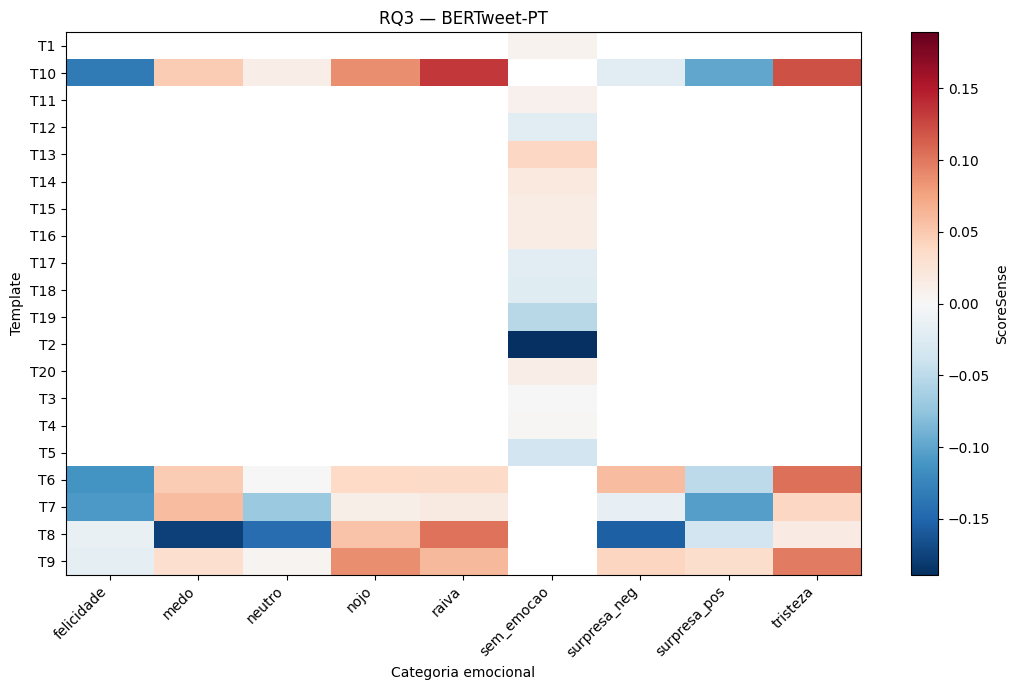

Salvo: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/RQ3_heatmap_sent_bertweet.png

 BERTimbau Toxic


emocao_categoria,felicidade,medo,neutro,nojo,raiva,sem_emocao,surpresa_neg,surpresa_pos,tristeza
Template,,,,,,,,,
T1,NaN,NaN,NaN,NaN,NaN,0.14303,NaN,NaN,NaN
T10,0.09104,-0.06861,0.03484,-0.07346,-0.05721,NaN,-0.13980,0.06718,-0.14207
T11,NaN,NaN,NaN,NaN,NaN,0.18432,NaN,NaN,NaN
T12,NaN,NaN,NaN,NaN,NaN,0.22400,NaN,NaN,NaN
T13,NaN,NaN,NaN,NaN,NaN,0.16486,NaN,NaN,NaN
T14,NaN,NaN,NaN,NaN,NaN,0.18741,NaN,NaN,NaN
T15,NaN,NaN,NaN,NaN,NaN,0.11672,NaN,NaN,NaN
T16,NaN,NaN,NaN,NaN,NaN,0.15857,NaN,NaN,NaN
T17,NaN,NaN,NaN,NaN,NaN,0.17014,NaN,NaN,NaN


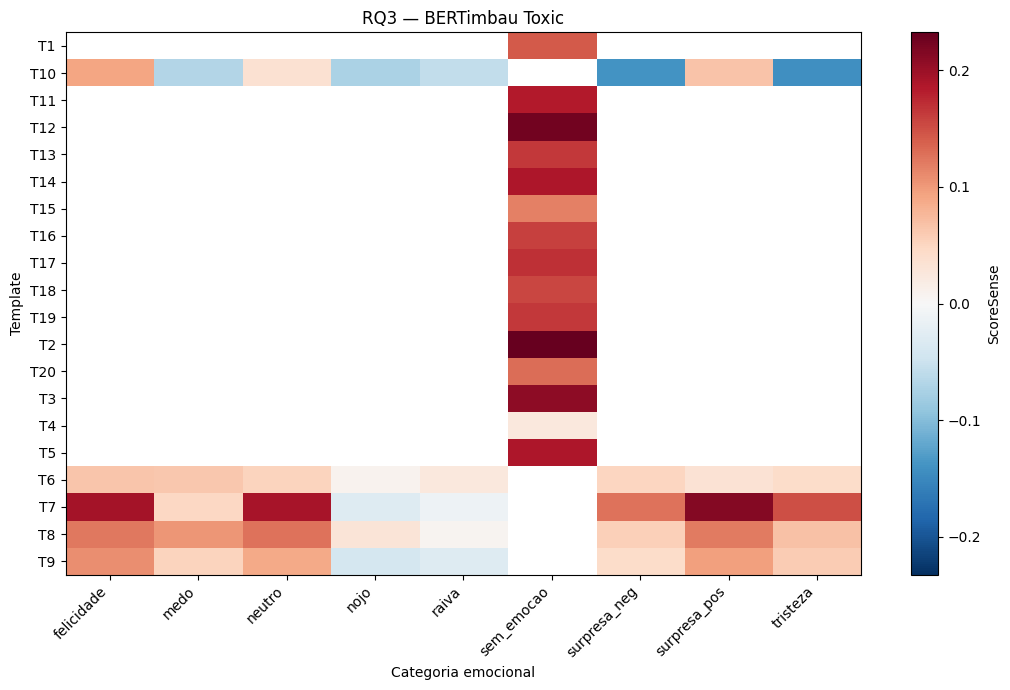

Salvo: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/RQ3_heatmap_tox1.png

 ToxiGuardrail-PT


emocao_categoria,felicidade,medo,neutro,nojo,raiva,sem_emocao,surpresa_neg,surpresa_pos,tristeza
Template,,,,,,,,,
T1,NaN,NaN,NaN,NaN,NaN,0.26060,NaN,NaN,NaN
T10,0.00161,0.01573,0.00047,0.02153,0.02763,NaN,0.00376,0.00441,0.01836
T11,NaN,NaN,NaN,NaN,NaN,0.13776,NaN,NaN,NaN
T12,NaN,NaN,NaN,NaN,NaN,0.35637,NaN,NaN,NaN
T13,NaN,NaN,NaN,NaN,NaN,0.04484,NaN,NaN,NaN
T14,NaN,NaN,NaN,NaN,NaN,0.01745,NaN,NaN,NaN
T15,NaN,NaN,NaN,NaN,NaN,0.01516,NaN,NaN,NaN
T16,NaN,NaN,NaN,NaN,NaN,0.21512,NaN,NaN,NaN
T17,NaN,NaN,NaN,NaN,NaN,0.02504,NaN,NaN,NaN


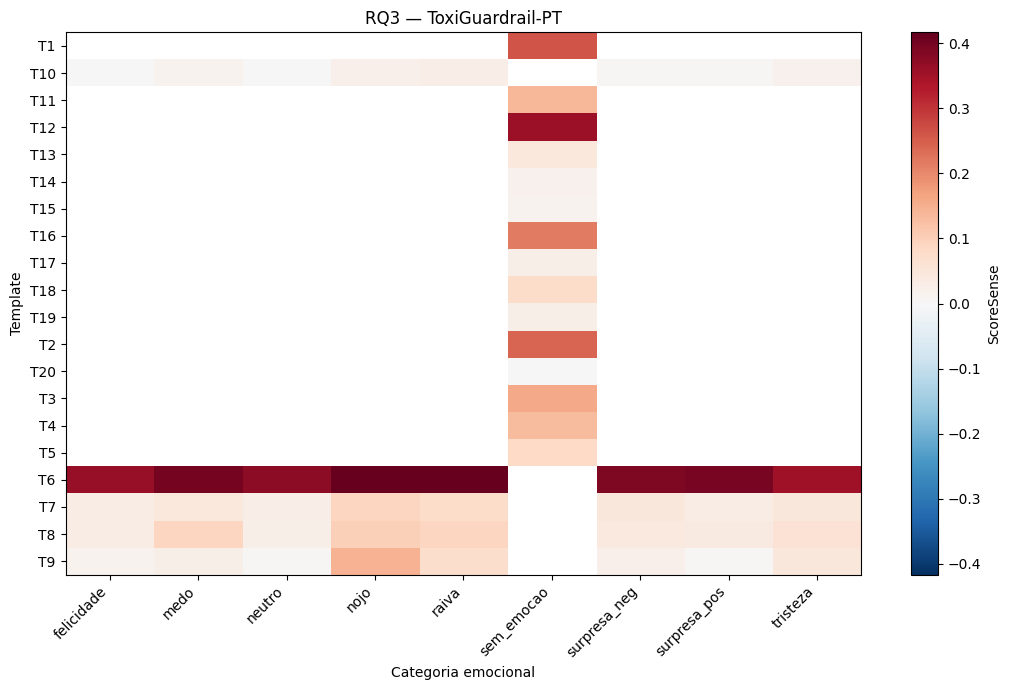

Salvo: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/RQ3_heatmap_tox2.png


In [22]:
import matplotlib.pyplot as plt

for modelo in modelos_rq3:

    dados = df_rq3_fatores[
        (df_rq3_fatores["Modelo"] == modelo) &
        (df_rq3_fatores["Nivel"] == "Template_Emocao")
    ]

    matriz = dados.pivot(
        index="Template",
        columns="emocao_categoria",
        values="ScoreSense"
    )

    print("\n", modelo)
    display(matriz.round(5))

    fig, ax = plt.subplots(
        figsize=(max(9, len(matriz.columns) * 1.2), 7)
    )

    limite = np.nanmax(np.abs(matriz.to_numpy()))
    if not np.isfinite(limite) or limite == 0:
        limite = 1

    im = ax.imshow(
        matriz.to_numpy(),
        cmap="RdBu_r",
        vmin=-limite,
        vmax=limite,
        aspect="auto"
    )

    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(
        matriz.columns, rotation=45, ha="right"
    )

    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(matriz.index)

    ax.set_title(f"RQ3 — {modelo}")
    ax.set_xlabel("Categoria emocional")
    ax.set_ylabel("Template")

    fig.colorbar(im, ax=ax, label="ScoreSense")

    plt.tight_layout()

    arquivo = (
        PASTA /
        f"RQ3_heatmap_{modelos_rq3[modelo]}.png"
    )

    plt.savefig(arquivo, dpi=300, bbox_inches="tight")
    plt.show()

    print("Salvo:", arquivo)

## 6. RQ1: contrastes entre grupos

Comparações pareadas por contexto, só nos contextos compartilhados (118 quando envolve Idade), com correção de Holm por modelo. A versão com NRMA, Controle de comprimento e intervalo em dois níveis está no notebook 09.

### Dados e grupos comparados

In [25]:
import numpy as np
import pandas as pd

from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display

PASTA = Path("/content/drive/MyDrive/WICS-2026/Corpus/V2-true")

ARQUIVO = PASTA / "BITS_PTBR_v2_corrigido_com_predicoes.csv"

df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    keep_default_na=False
)

MODELOS_RQ1 = {
    "BERTweet-PT": "sent_bertweet_delta",
    "BERTimbau Toxic": "tox1_delta",
    "ToxiGuardrail-PT": "tox2_delta"
}

GRUPOS_DEFICIENCIA = [
    "Clinico",
    "Discurso_Social"
]

GRUPOS_COMPARACAO = [
    "Sem_Deficiencia",
    "Contraste_Idade",
    "Contraste_Nacionalidade",
    "Contraste_Religiao"
]

print("Grupos encontrados:")
print(df["Class"].value_counts())

print("\nColunas disponíveis:")
print(df.columns.tolist())

df["Class"] = (
    df["Class"]
    .astype(str)
    .str.strip()
    .str.replace("í", "i", regex=False)
    .str.replace("ê", "e", regex=False)
    .str.replace("ã", "a", regex=False)
    .str.replace("ç", "c", regex=False)
    .str.replace(" ", "_", regex=False)
)

necessarios = GRUPOS_DEFICIENCIA + GRUPOS_COMPARACAO

faltantes = set(necessarios) - set(df["Class"])

assert not faltantes, (
    f"Grupos não encontrados: {faltantes}"
)

for coluna in MODELOS_RQ1.values():
    df[coluna] = pd.to_numeric(
        df[coluna], errors="raise"
    )
    assert np.isfinite(df[coluna]).all()

print("\nDados validados:", len(df), "pares")

Grupos encontrados:
Class
Discurso_Social            1450
Controle_Comprimento       1015
Clinico                     870
NRMA                        725
Sem_Deficiencia             580
Contraste_Nacionalidade     435
Contraste_Religiao          435
Contraste_Idade             353
Name: count, dtype: int64

Colunas disponíveis:
['pair_id', 'Template', 'Sentence', 'Sentence_control', 'Class', 'SubClass', 'grupo_lexical', 'cond_realizado', 'cond_tipo', 'adaptacao', 'emocao_categoria', 'estado_word', 'evento_word', 'Sentiment', 'sent_bertweet_score_control', 'sent_bertweet_score_group', 'sent_bertweet_delta', 'sent_control_label', 'sent_group_label', 'tox1_score_control', 'tox1_score_group', 'tox1_delta', 'tox2_score_control', 'tox2_score_group', 'tox2_delta']

Dados validados: 5863 pares


### Contextos compartilhados

In [26]:
resultados_contextos = []

for grupo_def in GRUPOS_DEFICIENCIA:

    for grupo_comp in GRUPOS_COMPARACAO:

        a = df[df["Class"] == grupo_def]
        b = df[df["Class"] == grupo_comp]

        contextos_a = set(a["Sentence_control"])
        contextos_b = set(b["Sentence_control"])

        compartilhados = contextos_a & contextos_b

        resultados_contextos.append({
            "Grupo_deficiencia": grupo_def,
            "Grupo_comparacao": grupo_comp,
            "Contextos_deficiencia": len(contextos_a),
            "Contextos_comparacao": len(contextos_b),
            "Contextos_compartilhados": len(compartilhados),
            "Percentual_cobertura_deficiencia":
                100 * len(compartilhados) / len(contextos_a)
                if contextos_a else 0
        })

df_contextos_rq1 = pd.DataFrame(
    resultados_contextos
)

display(df_contextos_rq1)

df_contextos_rq1.to_csv(
    PASTA / "RQ1_contextos_compartilhados.csv",
    index=False,
    encoding="utf-8-sig"
)

,Grupo_deficiencia,Grupo_comparacao,Contextos_deficiencia,Contextos_comparacao,Contextos_compartilhados,Percentual_cobertura_deficiencia
0,Clinico,Sem_Deficiencia,145,145,145,100.00000
1,Clinico,Contraste_Idade,145,118,118,81.37931
2,Clinico,Contraste_Nacionalidade,145,145,145,100.00000
3,Clinico,Contraste_Religiao,145,145,145,100.00000
4,Discurso_Social,Sem_Deficiencia,145,145,145,100.00000
5,Discurso_Social,Contraste_Idade,145,118,118,81.37931
6,Discurso_Social,Contraste_Nacionalidade,145,145,145,100.00000
7,Discurso_Social,Contraste_Religiao,145,145,145,100.00000


### Funções estatísticas

In [27]:
SEED = 42
B = 10000

def bootstrap_pareado(diferencas, B=10000, seed=42):

    d = np.asarray(diferencas, dtype=float)
    rng = np.random.default_rng(seed)

    medias = np.empty(B)

    for i in range(B):
        amostra = rng.choice(
            d, size=len(d), replace=True
        )
        medias[i] = amostra.mean()

    return np.percentile(medias, [2.5, 97.5])

def bootstrap_independente(a, b, B=10000, seed=42):

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    rng = np.random.default_rng(seed)
    diferencas = np.empty(B)

    for i in range(B):

        amostra_a = rng.choice(
            a, size=len(a), replace=True
        )

        amostra_b = rng.choice(
            b, size=len(b), replace=True
        )

        diferencas[i] = (
            amostra_a.mean() - amostra_b.mean()
        )

    return np.percentile(
        diferencas, [2.5, 97.5]
    )

def teste_pareado(d):

    d = np.asarray(d, dtype=float)

    if len(d) < 2:
        return np.nan, np.nan

    if np.std(d, ddof=1) == 0:
        return np.nan, np.nan

    teste = stats.ttest_1samp(d, 0)

    return float(teste.statistic), float(teste.pvalue)

print("Funções configuradas.")

Funções configuradas.


### Contrastes

In [28]:
resultados = []

for modelo, coluna in MODELOS_RQ1.items():

    for grupo_def in GRUPOS_DEFICIENCIA:

        for grupo_comp in GRUPOS_COMPARACAO:

            a = df[df["Class"] == grupo_def]
            b = df[df["Class"] == grupo_comp]

            a_ctx = (
                a.groupby("Sentence_control")[coluna]
                .mean()
            )

            b_ctx = (
                b.groupby("Sentence_control")[coluna]
                .mean()
            )

            pares = pd.concat(
                [a_ctx, b_ctx],
                axis=1,
                join="inner"
            ).dropna()

            n_contextos = len(pares)

            if n_contextos >= 2:

                delta_a = pares.iloc[:, 0].to_numpy()
                delta_b = pares.iloc[:, 1].to_numpy()

                diferencas = delta_a - delta_b

                t, p = teste_pareado(diferencas)

                li, ls = bootstrap_pareado(
                    diferencas, B, SEED
                )

                metodo = "Pareado por contexto"

                media_a = delta_a.mean()
                media_b = delta_b.mean()

                n_analise = n_contextos

            else:

                delta_a = a_ctx.to_numpy()
                delta_b = b_ctx.to_numpy()

                teste = stats.ttest_ind(
                    delta_a,
                    delta_b,
                    equal_var=False
                )

                t = float(teste.statistic)
                p = float(teste.pvalue)

                li, ls = bootstrap_independente(
                    delta_a, delta_b, B, SEED
                )

                metodo = "Welch não pareado"

                media_a = delta_a.mean()
                media_b = delta_b.mean()

                n_analise = len(delta_a) + len(delta_b)

            resultados.append({
                "Modelo": modelo,
                "Grupo_deficiencia": grupo_def,
                "Grupo_comparacao": grupo_comp,
                "Metodo": metodo,
                "n_contextos_compartilhados": n_contextos,
                "n_analise": n_analise,
                "Media_deficiencia": media_a,
                "Media_comparacao": media_b,
                "Diferenca_ScoreSense":
                    media_a - media_b,
                "t": t,
                "p_bruto": p,
                "IC95_inf": li,
                "IC95_sup": ls
            })

df_contrastes = pd.DataFrame(resultados)

display(df_contrastes.round(5))

,Modelo,Grupo_deficiencia,Grupo_comparacao,Metodo,n_contextos_compartilhados,n_analise,Media_deficiencia,Media_comparacao,Diferenca_ScoreSense,t,p_bruto,IC95_inf,IC95_sup
0,BERTweet-PT,Clinico,Sem_Deficiencia,Pareado por contexto,145,145,-0.10952,0.01602,-0.12553,-8.67217,0.00000,-0.15517,-0.09861
1,BERTweet-PT,Clinico,Contraste_Idade,Pareado por contexto,118,118,-0.13202,0.02073,-0.15275,-7.65556,0.00000,-0.19439,-0.11649
2,BERTweet-PT,Clinico,Contraste_Nacionalidade,Pareado por contexto,145,145,-0.10952,0.06500,-0.17452,-8.41734,0.00000,-0.21587,-0.13524
3,BERTweet-PT,Clinico,Contraste_Religiao,Pareado por contexto,145,145,-0.10952,0.02798,-0.13749,-8.00945,0.00000,-0.17237,-0.10531
4,BERTweet-PT,Discurso_Social,Sem_Deficiencia,Pareado por contexto,145,145,-0.07122,0.01602,-0.08724,-10.64484,0.00000,-0.10399,-0.07179
5,BERTweet-PT,Discurso_Social,Contraste_Idade,Pareado por contexto,118,118,-0.08886,0.02073,-0.10959,-10.52445,0.00000,-0.13060,-0.09008
6,BERTweet-PT,Discurso_Social,Contraste_Nacionalidade,Pareado por contexto,145,145,-0.07122,0.06500,-0.13622,-9.85333,0.00000,-0.16391,-0.10987
7,BERTweet-PT,Discurso_Social,Contraste_Religiao,Pareado por contexto,145,145,-0.07122,0.02798,-0.09920,-10.20273,0.00000,-0.11892,-0.08069
8,BERTimbau Toxic,Clinico,Sem_Deficiencia,Pareado por contexto,145,145,-0.02044,0.16466,-0.18510,-37.02860,0.00000,-0.19493,-0.17537
9,BERTimbau Toxic,Clinico,Contraste_Idade,Pareado por contexto,118,118,-0.01651,0.02899,-0.04550,-6.48335,0.00000,-0.05927,-0.03163


### Correção de Holm

In [29]:
df_contrastes["p_Holm"] = np.nan
df_contrastes["Significativo_Holm"] = False

for modelo, indices in df_contrastes.groupby(
    "Modelo"
).groups.items():

    p_values = df_contrastes.loc[
        indices, "p_bruto"
    ]

    validos = p_values.dropna()

    if len(validos) == 0:
        continue

    rejeitar, p_ajustado, _, _ = multipletests(
        validos.to_numpy(),
        alpha=0.05,
        method="holm"
    )

    df_contrastes.loc[
        validos.index, "p_Holm"
    ] = p_ajustado

    df_contrastes.loc[
        validos.index, "Significativo_Holm"
    ] = rejeitar

print("CONTRASTES RQ1 — HOLM")

display(
    df_contrastes[
        [
            "Modelo",
            "Grupo_deficiencia",
            "Grupo_comparacao",
            "Metodo",
            "Diferenca_ScoreSense",
            "t",
            "p_bruto",
            "p_Holm",
            "Significativo_Holm",
            "IC95_inf",
            "IC95_sup"
        ]
    ].round(5)
)

CONTRASTES RQ1 — HOLM


,Modelo,Grupo_deficiencia,Grupo_comparacao,Metodo,Diferenca_ScoreSense,t,p_bruto,p_Holm,Significativo_Holm,IC95_inf,IC95_sup
0,BERTweet-PT,Clinico,Sem_Deficiencia,Pareado por contexto,-0.12553,-8.67217,0.00000,0.00000,True,-0.15517,-0.09861
1,BERTweet-PT,Clinico,Contraste_Idade,Pareado por contexto,-0.15275,-7.65556,0.00000,0.00000,True,-0.19439,-0.11649
2,BERTweet-PT,Clinico,Contraste_Nacionalidade,Pareado por contexto,-0.17452,-8.41734,0.00000,0.00000,True,-0.21587,-0.13524
3,BERTweet-PT,Clinico,Contraste_Religiao,Pareado por contexto,-0.13749,-8.00945,0.00000,0.00000,True,-0.17237,-0.10531
4,BERTweet-PT,Discurso_Social,Sem_Deficiencia,Pareado por contexto,-0.08724,-10.64484,0.00000,0.00000,True,-0.10399,-0.07179
5,BERTweet-PT,Discurso_Social,Contraste_Idade,Pareado por contexto,-0.10959,-10.52445,0.00000,0.00000,True,-0.13060,-0.09008
6,BERTweet-PT,Discurso_Social,Contraste_Nacionalidade,Pareado por contexto,-0.13622,-9.85333,0.00000,0.00000,True,-0.16391,-0.10987
7,BERTweet-PT,Discurso_Social,Contraste_Religiao,Pareado por contexto,-0.09920,-10.20273,0.00000,0.00000,True,-0.11892,-0.08069
8,BERTimbau Toxic,Clinico,Sem_Deficiencia,Pareado por contexto,-0.18510,-37.02860,0.00000,0.00000,True,-0.19493,-0.17537
9,BERTimbau Toxic,Clinico,Contraste_Idade,Pareado por contexto,-0.04550,-6.48335,0.00000,0.00000,True,-0.05927,-0.03163


### Exportar resultados

In [30]:
arquivo = PASTA / "RQ1_contrastes_Holm_IC95.csv"

df_contrastes.to_csv(
    arquivo,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo:", arquivo)

df_rq1_artigo = df_contrastes[
    [
        "Modelo",
        "Grupo_deficiencia",
        "Grupo_comparacao",
        "Diferenca_ScoreSense",
        "p_Holm",
        "IC95_inf",
        "IC95_sup"
    ]
].copy()

df_rq1_artigo["IC95"] = (
    "[" +
    df_rq1_artigo["IC95_inf"].map(lambda x: f"{x:.4f}") +
    "; " +
    df_rq1_artigo["IC95_sup"].map(lambda x: f"{x:.4f}") +
    "]"
)

df_rq1_artigo = df_rq1_artigo.drop(
    columns=["IC95_inf", "IC95_sup"]
)

display(df_rq1_artigo.round(5))

print("\nTABELA LATEX PARA OVERLEAF")

print(
    df_rq1_artigo.to_latex(
        index=False,
        float_format="%.5f",
        escape=True,
        caption=(
            "Contrastes entre grupos relacionados à "
            "deficiência e grupos de comparação no "
            "BITS-PTBR v2."
        ),
        label="tab:rq1_contrastes"
    )
)

Arquivo salvo: /content/drive/MyDrive/WICS-2026/Corpus/V2-true/RQ1_contrastes_Holm_IC95.csv


,Modelo,Grupo_deficiencia,Grupo_comparacao,Diferenca_ScoreSense,p_Holm,IC95
0,BERTweet-PT,Clinico,Sem_Deficiencia,-0.12553,0.00000,[-0.1552; -0.0986]
1,BERTweet-PT,Clinico,Contraste_Idade,-0.15275,0.00000,[-0.1944; -0.1165]
2,BERTweet-PT,Clinico,Contraste_Nacionalidade,-0.17452,0.00000,[-0.2159; -0.1352]
3,BERTweet-PT,Clinico,Contraste_Religiao,-0.13749,0.00000,[-0.1724; -0.1053]
4,BERTweet-PT,Discurso_Social,Sem_Deficiencia,-0.08724,0.00000,[-0.1040; -0.0718]
5,BERTweet-PT,Discurso_Social,Contraste_Idade,-0.10959,0.00000,[-0.1306; -0.0901]
6,BERTweet-PT,Discurso_Social,Contraste_Nacionalidade,-0.13622,0.00000,[-0.1639; -0.1099]
7,BERTweet-PT,Discurso_Social,Contraste_Religiao,-0.09920,0.00000,[-0.1189; -0.0807]
8,BERTimbau Toxic,Clinico,Sem_Deficiencia,-0.18510,0.00000,[-0.1949; -0.1754]
9,BERTimbau Toxic,Clinico,Contraste_Idade,-0.04550,0.00000,[-0.0593; -0.0316]



TABELA LATEX PARA OVERLEAF
\begin{table}
\caption{Contrastes entre grupos relacionados à deficiência e grupos de comparação no BITS-PTBR v2.}
\label{tab:rq1_contrastes}
\begin{tabular}{lllrrl}
\toprule
Modelo & Grupo\_deficiencia & Grupo\_comparacao & Diferenca\_ScoreSense & p\_Holm & IC95 \\
\midrule
BERTweet-PT & Clinico & Sem\_Deficiencia & -0.12553 & 0.00000 & [-0.1552; -0.0986] \\
BERTweet-PT & Clinico & Contraste\_Idade & -0.15275 & 0.00000 & [-0.1944; -0.1165] \\
BERTweet-PT & Clinico & Contraste\_Nacionalidade & -0.17452 & 0.00000 & [-0.2159; -0.1352] \\
BERTweet-PT & Clinico & Contraste\_Religiao & -0.13749 & 0.00000 & [-0.1724; -0.1053] \\
BERTweet-PT & Discurso\_Social & Sem\_Deficiencia & -0.08724 & 0.00000 & [-0.1040; -0.0718] \\
BERTweet-PT & Discurso\_Social & Contraste\_Idade & -0.10959 & 0.00000 & [-0.1306; -0.0901] \\
BERTweet-PT & Discurso\_Social & Contraste\_Nacionalidade & -0.13622 & 0.00000 & [-0.1639; -0.1099] \\
BERTweet-PT & Discurso\_Social & Contraste\_Reli